<h1 style="text-align: center;">Used Car Price Prediction - Syarah.com</h1>
<h3 style="text-align: center;">Athiyyah Nisrina Husna & Firsa Adam</h3>

---

## **Section 0. Setup**

### **0.1 Import Library**

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score

import shap

import sys
sys.path.append('../src')

import joblib
import sklearn
import xgboost
from pathlib import Path



pd.set_option('display.max_columns', None)

### **0.2 Global Configuration**

In [72]:
RANDOM_STATE = 42

# Palet warna
BLUE = '#3498db'   # warna utama
RED = '#e74c3c'    # warna pembanding / highlight

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.titlecolor': '#1a1a2e',
    'axes.labelcolor': '#1a1a2e',
    'xtick.color': '#444444',
    'ytick.color': '#444444',
    'axes.grid': True,
    'grid.color': '#d0d0d0',
    'axes.axisbelow': True,
})

from matplotlib.ticker import FuncFormatter
sar_fmt = FuncFormatter(lambda x, _: f'{x:,.0f}')  # format angka 1,200,000

df = pd.read_csv('../data/processed/cars_clean.csv')
assert df.shape == (5487, 12), f"Shape tidak sesuai: {df.shape}"
assert df['Price'].isna().sum() == 0

## **Section 1. Data Splitting**
### **1.1 Feature and Target Definition**


Dataset yang digunakan pada tahap modeling adalah `cars_clean.csv`, yaitu hasil akhir dari notebook `1_Data_Preparation.ipynb`. Dataset ini berisi **5.487 listing** mobil bekas dari Syarah.com yang mencantumkan harga, dengan **12 kolom** yang terdiri dari 11 fitur dan 1 target. Listing berstatus Negotiable (2.577 listing) tidak disertakan karena tidak memiliki harga, dan disimpan terpisah di `cars_negotiable.csv` untuk digunakan sebagai data inferensi setelah model selesai dibangun.

Target yang diprediksi adalah `Price`, yaitu harga listing dalam Riyal Saudi (SAR) dengan rentang 5.000–1.150.000 SAR dan median 58.000 SAR. Berdasarkan hasil EDA, distribusi `Price` sangat condong ke kanan (skewness 3,74), sehingga pada tahap ini akan dibandingkan performa model dengan dan tanpa transformasi log1p pada target.

Fitur yang digunakan dikelompokkan berdasarkan tipe dan jumlah kategorinya, karena setiap kelompok memerlukan penanganan yang berbeda pada tahap preprocessing:

| Kelompok | Fitur | Keterangan |
|---|---|---|
| Numerik | `Year`, `Mileage`, `Engine_Size` | `Year` diubah menjadi `Car_Age` (umur mobil pada 2021) di dalam pipeline |
| Ordinal | `Options` | Urutan Standard < Semi Full < Full |
| Kategorikal (kategori sedikit) | `Origin`, `Fuel_Type`, `Gear_Type` | 2–3 kategori |
| Kategorikal (kategori banyak) | `Make`, `Type`, `Region`, `Color` | 60 merek, 385 model, 27 wilayah, 15 warna |

Dataset ini masih memiliki nilai kosong pada lima fitur, yaitu `Engine_Size` (1.189 baris), `Mileage` (387 baris), `Options` (39 baris), `Origin` (26 baris), dan `Gear_Type` (18 baris). Nilai kosong ini sengaja dibiarkan pada tahap Data Preparation dan akan diimputasi di dalam pipeline setelah train-test split, sehingga statistik imputasi hanya dihitung dari data train dan tidak terjadi data leakage.


In [73]:
NUM_FEATURES = ['Year', 'Mileage', 'Engine_Size']
ORD_FEATURES = ['Options']
LOW_CARD_FEATURES = ['Origin', 'Fuel_Type', 'Gear_Type']
HIGH_CARD_FEATURES = ['Make', 'Type', 'Region', 'Color']
FEATURES = NUM_FEATURES + ORD_FEATURES + LOW_CARD_FEATURES + HIGH_CARD_FEATURES
TARGET = 'Price'

X = df[FEATURES]
y = df[TARGET]


### **1.2 Train-Test Split**

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

assert len(X_train) + len(X_test) == len(df)
assert set(X_train.columns) == set(FEATURES)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (4389, 11) | Test: (1098, 11)


Data dibagi menjadi data train dan data test dengan proporsi 80:20, menghasilkan **4.389 listing** untuk training dan **1.098 listing** untuk testing. Data train digunakan untuk melatih model, memilih model terbaik melalui cross-validation, dan melakukan tuning hyperparameter, sedangkan data test hanya digunakan satu kali di akhir untuk mengukur performa model pada data yang belum pernah dilihat. Parameter `random_state` ditetapkan agar hasil pembagian data selalu sama setiap kali notebook dijalankan.

Pembagian data dilakukan sebelum preprocessing, karena langkah seperti imputasi dan encoding membutuhkan statistik dari data. Dengan membagi data lebih dulu, statistik tersebut hanya dihitung dari data train, sehingga informasi dari data test tidak ikut memengaruhi proses training.

## **Section 2. Data Preprocessing**

### **2.1 Feature Engineering**

Kode pada bagian ini disimpan ke `src/car_preprocessing.py` menggunakan `%%writefile`, sehingga fungsi dan class yang sama dapat digunakan kembali saat model di-load di aplikasi Streamlit.

In [75]:
%%writefile ../src/car_preprocessing.py
"""Custom transformer untuk pipeline prediksi harga mobil bekas Syarah.com."""
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

REFERENCE_YEAR = 2021


def add_car_age(X):
    """Mengubah Year menjadi Car_Age dengan acuan tahun pengumpulan data.

    Args:
        X: DataFrame yang memiliki kolom Year.

    Returns:
        DataFrame dengan kolom Year diganti menjadi Car_Age (minimal 0).
    """
    X = X.copy()
    X['Year'] = (REFERENCE_YEAR - X['Year']).clip(lower=0)
    return X.rename(columns={'Year': 'Car_Age'})


def car_age_feature_names(transformer, input_features):
    """Menyesuaikan nama kolom output agar Year tercatat sebagai Car_Age."""
    return np.array(['Car_Age' if col == 'Year' else col for col in input_features])


Overwriting ../src/car_preprocessing.py


Kolom `Year` diubah menjadi `Car_Age`, yaitu umur mobil saat data dikumpulkan pada tahun 2021. Umur mobil lebih mudah diinterpretasikan dibandingkan tahun produksi, karena berhubungan langsung dengan penurunan harga akibat pemakaian. Listing dengan tahun 2022 diberi umur 0, karena mobil tersebut merupakan model tahun berikutnya yang sudah dirilis saat data dikumpulkan.

### **2.2 Missing Value Imputation**

In [76]:
%%writefile -a ../src/car_preprocessing.py


class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Mengisi NaN dengan median bertingkat per kelompok yang dihitung dari data train.

    Args:
        target_col: Kolom yang akan diimputasi.
        group_levels: Daftar kelompok dari yang paling spesifik ke paling umum,
            misalnya [['Make', 'Type'], ['Make']]. Jika kelompok tidak ditemukan,
            digunakan level berikutnya, lalu median global.
    """

    def __init__(self, target_col, group_levels):
        self.target_col = target_col
        self.group_levels = group_levels

    def fit(self, X, y=None):
        self.medians_ = [
            X.groupby(g)[self.target_col].median().rename('_median').reset_index()
            for g in self.group_levels
        ]
        self.global_median_ = X[self.target_col].median()
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        for group, median in zip(self.group_levels, self.medians_):
            mask = X[self.target_col].isna()
            if not mask.any():
                break
            # merge mempertahankan urutan baris, sehingga hasilnya sejajar dengan mask
            fill = X.loc[mask, group].merge(median, on=group, how='left')['_median']
            X.loc[mask, self.target_col] = fill.to_numpy()
        X[self.target_col] = X[self.target_col].fillna(self.global_median_)
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

Appending to ../src/car_preprocessing.py


In [77]:
from car_preprocessing import REFERENCE_YEAR, add_car_age, car_age_feature_names, GroupMedianImputer

car_age_transformer = FunctionTransformer(add_car_age, feature_names_out=car_age_feature_names)

feature_imputer = Pipeline([
    ('car_age', car_age_transformer),
    ('engine_size', GroupMedianImputer('Engine_Size', [['Make', 'Type'], ['Make']])),
    ('mileage', GroupMedianImputer('Mileage', [['Car_Age']])),
])

Nilai kosong pada `Engine_Size` dan `Mileage` diimputasi menggunakan median dari mobil yang sejenis, bukan median keseluruhan data. `Engine_Size` diisi dengan median dari mobil dengan merek dan model yang sama (`Make` dan `Type`), sedangkan `Mileage` diisi dengan median dari mobil dengan umur yang sama (`Car_Age`). Ukuran mesin sangat bergantung pada model mobil. Jika model tersebut tidak memiliki data ukuran mesin di data train, digunakan median per `Make`, lalu median keseluruhan sebagai pilihan terakhir. Dengan cara ini, Toyota Camry yang kosong akan diisi dengan ukuran mesin Camry lain, bukan rata-rata seluruh mobil yang mencampur sedan kecil dan SUV besar.

Sementara itu, jarak tempuh sangat dipengaruhi oleh umur mobil, sehingga `Mileage` diisi dengan median dari mobil dengan `Car_Age` yang sama. Karena itu, langkah konversi `Year` menjadi `Car_Age` ditempatkan sebelum imputasi. Kedua imputer ini disusun sebagai transformer scikit-learn, sehingga median hanya dihitung dari data train saat `fit` dan diterapkan dengan nilai yang sama pada data test maupun data inferensi.

### **2.3 Encoding and Scaling**

In [78]:
NUM_FEATURES_PROCESSED = ['Car_Age', 'Mileage', 'Engine_Size']

options_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['Standard', 'Semi Full', 'Full']])),
])

low_card_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
])

# Untuk model tree-based
encoder_tree = ColumnTransformer([
    ('num', 'passthrough', NUM_FEATURES_PROCESSED),
    ('ord', options_encoder, ORD_FEATURES),
    ('low', low_card_encoder, LOW_CARD_FEATURES),
    ('high', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE), HIGH_CARD_FEATURES),
])

# Untuk model linear
encoder_linear = ColumnTransformer([
    ('num', StandardScaler(), NUM_FEATURES_PROCESSED),
    ('ord', options_encoder, ORD_FEATURES),
    ('low', low_card_encoder, LOW_CARD_FEATURES),
    ('high', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=3, sparse_output=False),HIGH_CARD_FEATURES),
])

preprocessor_tree = Pipeline([('imputer', clone(feature_imputer)), ('encoder', encoder_tree)])
preprocessor_linear = Pipeline([('imputer', clone(feature_imputer)), ('encoder', encoder_linear)])

**Penjelasan Preprocessing Pipeline**

1. **Numerik** (`Car_Age`, `Mileage`, `Engine_Size`)
    - Nilai kosong sudah diisi pada tahap 2.2, sehingga tidak perlu imputer lagi di tahap ini
    - Model tree-based: dibiarkan apa adanya (`passthrough`), karena model tree memisahkan data berdasarkan batas nilai sehingga tidak terpengaruh skala fitur
    - Model linear: distandarisasi dengan `StandardScaler`, karena skala `Mileage` (ratusan ribu km) jauh lebih besar dibandingkan `Car_Age` dan `Engine_Size`, sehingga koefisien model sulit dibandingkan tanpa standarisasi

2. **Ordinal** (`Options`)
    - Dipakai karena kategorinya memiliki urutan tingkatan yang bermakna (Standard < Semi Full < Full)
    - Urutan kategori didefinisikan secara manual, bukan diurutkan otomatis secara alfabetis, supaya sesuai dengan tingkat kelengkapan fitur yang sebenarnya
    - Nilai kosong (39 baris) diisi dengan modus

3. **One-Hot** (`Origin`, `Fuel_Type`, `Gear_Type`)
    - Dipakai untuk kolom kategorikal dengan 2–3 kategori, sehingga hanya menambah sedikit kolom
    - Nilai kosong diisi dengan modus karena jumlahnya kurang dari 1% data
    - `drop="first"` menghapus satu kolom pada setiap fitur, karena kategori yang di-drop sudah terwakili oleh kondisi semua kolom bernilai 0, sehingga jumlah kolom berkurang dan ketergantungan antar kolom pada model linear dapat dikurangi
    - `handle_unknown="ignore"` supaya kategori baru yang tidak ada di data train tidak menimbulkan error saat inferensi

4. **Banyak Kategori** (`Make`, `Type`, `Region`, `Color`)
    - Model tree-based menggunakan **target encoding**: setiap kategori diganti dengan rata-rata target kategori tersebut yang telah dihaluskan (smoothing) ke arah rata-rata global, sehingga 385 kategori `Type` cukup diwakili satu kolom. Pada model dengan transformasi log1p, rata-rata ini dihitung dari `Price` dalam skala log Cross-fitting saat training mencegah harga suatu listing ikut menentukan nilai encoding-nya sendiri
    - Model linear menggunakan **one-hot encoding**, karena model linear membutuhkan setiap kategori sebagai kolom terpisah. Kategori yang muncul kurang dari 3 kali di data train digabung menjadi satu kategori "lainnya" (`min_frequency=3`). Tanpa penggabungan ini, model mobil yang hanya muncul satu atau dua kali mendapat koefisien yang sangat besar, sehingga prediksinya bisa melonjak jauh di atas harga yang wajar. Kategori yang tidak ditemukan di data train juga akan masuk ke kategori "lainnya"


### **2.4 Preprocessing Validation**

In [79]:
for name, preprocessor in [('Tree', preprocessor_tree), ('Linear', preprocessor_linear)]:
    preprocessor.set_output(transform='pandas')
    X_train_prep = preprocessor.fit_transform(X_train, y_train)
    X_test_prep = preprocessor.transform(X_test)

    assert X_train_prep.isna().sum().sum() == 0, f"{name}: masih ada NaN di train"
    assert X_test_prep.isna().sum().sum() == 0, f"{name}: masih ada NaN di test"
    assert X_train_prep.shape[1] == X_test_prep.shape[1], f"{name}: jumlah kolom train dan test berbeda"
    assert len(X_train_prep) == len(X_train) and len(X_test_prep) == len(X_test), f"{name}: jumlah baris berubah"
    print(f"{name:6s} | Train: {X_train_prep.shape} | Test: {X_test_prep.shape}")

# Pastikan imputasi memakai median per kelompok, bukan hanya median global
check = clone(feature_imputer).fit(X_train).transform(X_test)
for col in ['Mileage', 'Engine_Size']:
    imputed_values = check.loc[X_test[col].isna(), col]
    assert imputed_values.nunique() > 1, f"{col}: semua nilai kosong diisi dengan nilai yang sama"
    print(f"{col}: {X_test[col].isna().sum()} nilai kosong diisi dengan {imputed_values.nunique()} nilai berbeda")

preprocessor_tree.fit_transform(X_train, y_train).head()

Tree   | Train: (4389, 13) | Test: (1098, 13)
Linear | Train: (4389, 282) | Test: (1098, 282)
Mileage: 85 nilai kosong diisi dengan 17 nilai berbeda
Engine_Size: 233 nilai kosong diisi dengan 33 nilai berbeda


,num__Car_Age,num__Mileage,num__Engine_Size,ord__Options,low__Origin_Other,low__Origin_Saudi,low__Fuel_Type_Gas,low__Fuel_Type_Hybrid,low__Gear_Type_Manual,high__Make,high__Type,high__Region,high__Color
3002,1,40000.0,4.0,1.0,0.0,1.0,1.0,0.0,0.0,80747.620659,88108.422206,94940.476105,78446.817623
2348,10,74000.0,2.5,2.0,0.0,1.0,1.0,0.0,0.0,136916.038716,92514.524304,80198.368989,78247.947480
2784,32,186000.0,4.0,2.0,1.0,0.0,1.0,0.0,0.0,181784.428699,64312.768623,82362.336310,71865.999602
5269,13,280000.0,5.3,0.0,0.0,1.0,1.0,0.0,0.0,77077.711879,93014.966922,95516.627554,77302.714140
2497,0,5352.0,4.0,1.0,0.0,1.0,1.0,0.0,0.0,79874.660400,148956.626781,81570.055412,106497.863329


Kedua preprocessor diuji dengan menerapkannya pada data train dan test untuk memastikan seluruh tahapan berjalan dengan benar. Pengecekan dilakukan pada empat hal, yaitu tidak ada nilai kosong yang tersisa, jumlah kolom pada data train dan test sama, jumlah baris tidak berubah setelah preprocessing, serta nilai kosong pada `Mileage` dan `Engine_Size` diisi menggunakan median per kelompok, bukan hanya satu nilai median global. Keempat pengecekan ini lolos, sehingga data siap digunakan untuk training.

Preprocessor untuk model tree-based menghasilkan **13 kolom**, karena fitur dengan kategori banyak cukup diwakili satu kolom per fitur melalui target encoding. Sementara itu, preprocessor untuk model linear menghasilkan **282 kolom**, karena setiap kategori pada `Make`, `Type`, `Region`, dan `Color` dijadikan kolom terpisah melalui one-hot encoding. Sebagian besar kolom tersebut berasal dari `Type`, yang tetap memiliki 187 model mobil setelah model yang muncul kurang dari 3 kali digabung menjadi satu kategori.

## **Section 3. Model Benchmarking**

### **3.1 Evaluation Setup**

In [80]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    'MAE': 'neg_mean_absolute_error',
    'MAPE': 'neg_mean_absolute_percentage_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

In [81]:
def fold_table(fold_scores):
    """Susun skor CV per fold, ditutup baris Mean dan Std.

    Args:
        fold_scores: Dict metrik -> array skor per fold (sudah bertanda positif).

    Returns:
        pd.DataFrame dengan baris Fold 1..k, Mean, dan Std.
    """
    table = pd.DataFrame(fold_scores)
    assert table.notna().all().all(), 'Ada skor fold yang kosong'
    table.index = [f'Fold {i + 1}' for i in range(len(table))]
    summary = pd.DataFrame({'Mean': table.mean(), 'Std': table.std(ddof=0)}).T
    return pd.concat([table, summary])


def style_folds(table):
    """Format angka tabel per fold."""
    return table.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE': '{:.1%}', 'R2': '{:.3f}'})

Setiap model dievaluasi menggunakan 5-fold cross-validation pada data train. Data train dibagi menjadi lima bagian, lalu model dilatih sebanyak lima kali, setiap kali menggunakan empat bagian sebagai data latih dan satu bagian sisanya sebagai data validasi. Skor akhir merupakan rata-rata dari kelima putaran tersebut, sehingga lebih stabil dibandingkan hanya mengandalkan satu kali pembagian data. Parameter `shuffle=True` digunakan agar setiap bagian berisi campuran listing yang acak.

Metrik yang digunakan mengikuti yang telah ditetapkan pada tahap Business Understanding, yaitu MAE dan MAPE sebagai metrik utama, dengan MAPE sebagai dasar pemilihan model, serta RMSE dan R² sebagai metrik pendukung. Karena scikit-learn memaksimalkan skor, metrik error dikembalikan dalam bentuk negatif dan akan diubah kembali menjadi positif saat ditampilkan.

### **3.2 Comparing Base Model Performance**

In [82]:
# Individual Models (Baseline)
regressors = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(),
    "Random Forest Regressor": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_STATE, n_jobs=4, verbosity=0),
    "LightGBM Regressor": LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
    "CatBoost Regressor": CatBoostRegressor(random_state=RANDOM_STATE, verbose=0, allow_writing_files=False),
    "Adaboost Regressor": AdaBoostRegressor(random_state=RANDOM_STATE),
    "Lasso Regression": Lasso(random_state=RANDOM_STATE),
}

# Model yang sensitif terhadap skala fitur memakai preprocessor linear
LINEAR_MODELS = ["Linear Regression", "KNN Regressor", "Lasso Regression"]


def build_estimator(name, model, log_target):
    """Menyusun pipeline preprocessing + model, dengan opsi transformasi log1p pada target.

    Args:
        name: Nama model, digunakan untuk memilih preprocessor yang sesuai.
        model: Estimator scikit-learn.
        log_target: Jika True, target ditransformasi dengan log1p saat training
            dan dikembalikan dengan expm1 saat prediksi.

    Returns:
        Estimator yang siap dilatih.
    """
    preprocessor = preprocessor_linear if name in LINEAR_MODELS else preprocessor_tree
    estimator = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('model', model),
    ])
    if log_target: # Transformasi price menjadi log1p
        estimator = TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1)
    return estimator

Model yang dibandingkan terdiri dari tiga kelompok. Linear Regression, Lasso Regression, dan KNN mewakili model sederhana yang menggunakan preprocessor linear, karena ketiganya sensitif terhadap skala fitur dan membutuhkan one-hot encoding. Decision Tree mewakili model berbasis aturan tunggal. Random Forest, AdaBoost, XGBoost, LightGBM, dan CatBoost mewakili model ensemble berbasis tree yang menggunakan preprocessor tree. Berdasarkan hasil EDA, model ensemble berpotensi lebih sesuai karena mampu menangkap interaksi antar fitur, misalnya penurunan harga akibat umur yang berbeda antara mobil premium dan non-premium. Seluruh model menggunakan hyperparameter default pada tahap ini, sedangkan tuning dilakukan pada Section 4 untuk model terpilih.

Setiap model diuji dua kali, yaitu dengan dan tanpa transformasi log1p pada target, untuk membuktikan pengaruh transformasi yang direkomendasikan pada tahap EDA. Linear Regression berperan sebagai model pembanding sesuai kriteria keberhasilan pada tahap Business Understanding.

In [83]:
def summarize_cv(name, log_label, scores):
    """Merangkum hasil cross_validate menjadi satu baris tabel."""
    row = {'Model': name, 'Log Target': log_label}
    for metric in SCORING:
        sign = 1 if metric == 'R2' else -1
        row[metric] = sign * scores[f'test_{metric}'].mean()
        row[f'{metric} Std'] = scores[f'test_{metric}'].std()
    row['R2 Train'] = scores['train_R2'].mean()
    return row
        
rows, benchmark_folds = [], {}
for name, model in regressors.items():
    for log_target in [False, True]:
        estimator = build_estimator(name, model, log_target)
        scores = cross_validate(estimator, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)
        rows.append(summarize_cv(name, 'Ya' if log_target else 'Tidak', scores))
        benchmark_folds[(name, 'Ya' if log_target else 'Tidak')] = {   
            m: (1 if m == 'R2' else -1) * scores[f'test_{m}'] for m in SCORING
        }

cv_results = pd.DataFrame(rows).sort_values('MAPE').reset_index(drop=True)   

assert len(cv_results) == 2 * len(regressors)                                
cv_results.style.format({                                                    
    'MAE': '{:,.0f}', 'MAE Std': '{:,.0f}',
    'RMSE': '{:,.0f}', 'RMSE Std': '{:,.0f}',
    'MAPE': '{:.1%}', 'MAPE Std': '{:.1%}',
    'R2': '{:.3f}', 'R2 Std': '{:.3f}', 'R2 Train': '{:.3f}',
})

c:\Users\Athiyyah\miniconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.598e+10, tolerance: 2.011e+09
  model = cd_fast.enet_coordinate_descent(
c:\Users\Athiyyah\miniconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.240e+10, tolerance: 2.109e+09
  model = cd_fast.enet_coordinate_descent(
c:\Users\Athiyyah\miniconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.896e+

,Model,Log Target,MAE,MAE Std,MAPE,MAPE Std,RMSE,RMSE Std,R2,R2 Std,R2 Train
0,CatBoost Regressor,Ya,"14,128",746,18.2%,0.4%,"32,191","3,963",0.820,0.034,0.920
1,LightGBM Regressor,Ya,"14,528",618,19.4%,0.1%,"32,173","3,010",0.819,0.032,0.899
2,XGBoost Regressor,Ya,"14,868",717,20.0%,0.8%,"32,977","3,126",0.812,0.025,0.926
3,Random Forest Regressor,Ya,"15,046",630,20.0%,0.3%,"34,185","4,301",0.797,0.041,0.904
4,CatBoost Regressor,Tidak,"14,492",883,21.6%,0.6%,"32,028","4,385",0.822,0.038,0.926
5,Linear Regression,Ya,"16,164","1,433",22.3%,0.7%,"34,675","6,289",0.793,0.050,0.831
6,LightGBM Regressor,Tidak,"15,071",863,22.6%,0.7%,"32,577","4,456",0.816,0.038,0.909
7,Random Forest Regressor,Tidak,"15,158","1,049",22.8%,0.8%,"34,321","5,380",0.796,0.047,0.896
8,XGBoost Regressor,Tidak,"15,140",853,22.9%,0.8%,"33,044","4,618",0.809,0.045,0.929
9,KNN Regressor,Ya,"18,572","1,309",27.7%,1.1%,"38,422","4,836",0.747,0.032,0.824


In [84]:
for name in ['CatBoost Regressor', 'XGBoost Regressor', 'LightGBM Regressor']:
    print(name)
    display(style_folds(fold_table(benchmark_folds[(name, 'Ya')])))

CatBoost Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,497",17.9%,"34,754",0.809
Fold 2,"13,415",18.1%,"34,542",0.771
Fold 3,"13,092",18.2%,"26,388",0.845
Fold 4,"14,584",19.0%,"28,612",0.871
Fold 5,"15,055",18.0%,"36,658",0.804
Mean,"14,128",18.2%,"32,191",0.820
Std,746,0.4%,"3,963",0.034


XGBoost Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,213",18.8%,"33,599",0.822
Fold 2,"14,454",19.9%,"35,125",0.764
Fold 3,"14,240",20.6%,"26,868",0.839
Fold 4,"15,981",21.0%,"33,952",0.818
Fold 5,"15,451",19.4%,"35,339",0.818
Mean,"14,868",20.0%,"32,977",0.812
Std,717,0.8%,"3,126",0.025


LightGBM Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,414",19.4%,"32,723",0.831
Fold 2,"13,798",19.2%,"34,169",0.776
Fold 3,"14,045",19.5%,"29,132",0.811
Fold 4,"14,836",19.5%,"28,443",0.872
Fold 5,"15,545",19.3%,"36,399",0.807
Mean,"14,528",19.4%,"32,173",0.819
Std,618,0.1%,"3,010",0.032


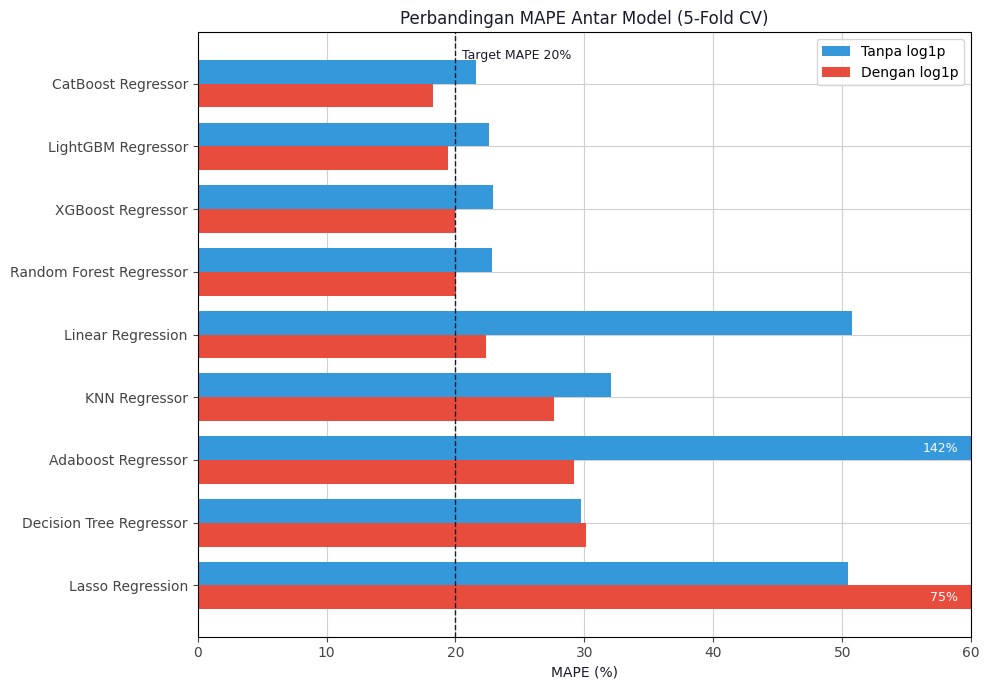

In [85]:
mape = cv_results.pivot(index='Model', columns='Log Target', values='MAPE') * 100
mape = mape.loc[mape.min(axis=1).sort_values(ascending=False).index]

X_MAX = 60
fig, ax = plt.subplots(figsize=(10, 7))
y_pos = np.arange(len(mape))
height = 0.38

bars = {
    'Tidak': (BLUE, 'Tanpa log1p', height / 2),
    'Ya': (RED, 'Dengan log1p', -height / 2),
}
for col, (color, label, offset) in bars.items():
    ax.barh(y_pos + offset, mape[col], height=height, color=color, label=label)
    # Label untuk bar yang melebihi batas sumbu
    for i, value in enumerate(mape[col]):
        if value > X_MAX:
            ax.text(X_MAX - 1, i + offset, f'{value:.0f}%', va='center', ha='right', color='white', fontsize=9)

ax.axvline(20, color='#1a1a2e', linestyle='--', linewidth=1)
ax.text(20.5, len(mape) - 0.6, 'Target MAPE 20%', color='#1a1a2e', fontsize=9)

ax.set_yticks(y_pos, mape.index)
ax.set_xlim(0, X_MAX)
ax.set_xlabel('MAPE (%)')
ax.set_title('Perbandingan MAPE Antar Model (5-Fold CV)')
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

Sebagai pembanding, Linear Regression dengan transformasi log1p menghasilkan MAPE 22,3%, MAE sekitar 16.160 SAR, dan R² 0,793. Model dianggap layak jika menghasilkan MAE dan MAPE lebih rendah dari angka ini, sesuai kriteria keberhasilan pada tahap Business Understanding. Empat model ensemble berhasil melampauinya, yaitu CatBoost, LightGBM, XGBoost, dan Random Forest, sedangkan KNN, AdaBoost, Decision Tree, dan Lasso menghasilkan performa yang lebih buruk.

| Temuan | Penjelasan |
|---|---|
| Pengaruh log1p | MAPE turun pada hampir semua model, paling besar pada Linear Regression (50,8% → 22,3%) dan konsisten pada model ensemble (CatBoost 21,6% → 18,2%). R² pada Random Forest dan tiga model boosting (CatBoost, LightGBM, XGBoost) relatif tidak berubah (selisih maksimal 0,003), sehingga log1p menurunkan error persentase tanpa mengorbankan kemampuan model menjelaskan variasi harga. |
| Lasso memburuk dengan log1p | `alpha=1.0` default terlalu besar untuk target berskala log (8–14), sehingga seluruh koefisien menjadi nol dan model memprediksi satu nilai yang sama untuk semua mobil. |
| AdaBoost tanpa log1p tidak stabil | MAPE mencapai 142,1%, karena model memberi bobot berlebih pada mobil berharga sangat tinggi. |
| Overfitting | Selisih R² train dan validasi sekitar 0,08 (LightGBM), 0,10 (CatBoost), dan 0,11 (XGBoost), masih wajar untuk model ensemble dengan hyperparameter default. |

CatBoost dengan log1p menjadi model terbaik dengan MAPE 18,2%, MAE sekitar 14.130 SAR, dan R² 0,820, sehingga sudah memenuhi target MAPE ≤ 20% dan berada tepat di ambang target R² ≥ 0,82 sebelum tuning. LightGBM berada di posisi kedua dengan MAPE 19,4% dan R² 0,819, diikuti XGBoost dengan MAPE 20,0% dan R² 0,812. Ketiga model ini merupakan model boosting berbasis tree dengan MAPE paling rendah, sehingga dipilih untuk dilanjutkan ke tahap hyperparameter tuning pada Section 4 dengan transformasi log1p.

## **Section 4. Hyperparameter Tuning**

### **4.1 Tuning Setup**

In [86]:
def base_pipeline(model):
    """Menyusun pipeline preprocessing tree + model."""
    return Pipeline([('preprocessor', clone(preprocessor_tree)), ('model', model)])


def with_log_prefix(params):
    """Menambahkan prefix 'regressor__' karena pipeline dibungkus TransformedTargetRegressor."""
    if isinstance(params, list):
        return [with_log_prefix(p) for p in params]
    return {f'regressor__{key}': value for key, value in params.items()}


experiments = {
    "CatBoost Regressor": {
        "pipeline": base_pipeline(
            CatBoostRegressor(random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)
        ),
        "params": [
            # Skenario 1: Bayesian bootstrap (default CatBoost)
            {
                "model__iterations": randint(300, 1200),
                "model__depth": randint(4, 9),
                "model__learning_rate": uniform(0.01, 0.2),
                "model__l2_leaf_reg": uniform(3, 7),
                "model__bootstrap_type": ["Bayesian"],
                "model__bagging_temperature": uniform(0, 5),
                "model__min_data_in_leaf": randint(10, 64),
                "model__random_strength": uniform(0, 5),
                "model__border_count": randint(32, 255),
                "model__leaf_estimation_iterations": randint(1, 10),
            },
            # Skenario 2: Bernoulli/MVS bootstrap
            {
                "model__iterations": randint(300, 1200),
                "model__depth": randint(4, 9),
                "model__learning_rate": uniform(0.01, 0.2),
                "model__l2_leaf_reg": uniform(3, 7),
                "model__bootstrap_type": ["Bernoulli", "MVS"],
                "model__subsample": uniform(0.6, 0.35),
                "model__min_data_in_leaf": randint(10, 64),
                "model__random_strength": uniform(0, 5),
                "model__border_count": randint(32, 255),
                "model__leaf_estimation_iterations": randint(1, 10),
            },
        ],
    },

    "XGBoost Regressor": {
        "pipeline": base_pipeline(
            XGBRegressor(random_state=RANDOM_STATE, n_jobs=4, verbosity=0)
        ),
        "params": [
            # Skenario 1: pertumbuhan pohon per level kedalaman
            {
                "model__grow_policy": ["depthwise"],
                "model__n_estimators": randint(300, 1200),
                "model__max_depth": randint(3, 9),
                "model__learning_rate": uniform(0.01, 0.2),
                "model__subsample": uniform(0.5, 0.25),
                "model__colsample_bytree": uniform(0.5, 0.25),
                "model__min_child_weight": randint(5, 25),
                "model__reg_alpha": uniform(0.1, 3.0),
                "model__reg_lambda": uniform(1.0, 5.0),
                "model__gamma": uniform(0, 0.3),
            },
            # Skenario 2: pertumbuhan pohon per daun dengan error terbesar
            {
                "model__grow_policy": ["lossguide"],
                "model__tree_method": ["hist"],
                "model__max_leaves": randint(20, 50),
                "model__n_estimators": randint(300, 1200),
                "model__learning_rate": uniform(0.01, 0.2),
                "model__subsample": uniform(0.5, 0.25),
                "model__colsample_bytree": uniform(0.5, 0.25),
                "model__min_child_weight": randint(5, 25),
                "model__reg_alpha": uniform(0.1, 3.0),
                "model__reg_lambda": uniform(1.0, 5.0),
                "model__gamma": uniform(0, 0.3),
            },
        ],
    },

    "LightGBM Regressor": {
        "pipeline": base_pipeline(
            LGBMRegressor(random_state=RANDOM_STATE, verbose=-1)
        ),
        "params": {
            "model__n_estimators": randint(300, 1200),
            "model__max_depth": randint(3, 9),
            "model__learning_rate": uniform(0.01, 0.2),
            "model__num_leaves": randint(20, 60),
            "model__subsample": uniform(0.6, 0.35),
            "model__bagging_freq": randint(1, 7),
            "model__colsample_bytree": uniform(0.5, 0.45),
            "model__min_child_samples": randint(20, 80),
            "model__reg_alpha": uniform(0.5, 3.0),
            "model__reg_lambda": uniform(0.5, 5.0),
            "model__min_split_gain": uniform(0, 0.1),
            "model__min_child_weight": uniform(0.001, 10),
        },
    },
}

### **4.2 Randomized Search**

In [87]:
searches = {}
for name, experiment in experiments.items():
    search = RandomizedSearchCV(
        estimator=TransformedTargetRegressor(
            regressor=experiment["pipeline"], func=np.log1p, inverse_func=np.expm1 # Dirubah kembali ke SAR
        ),
        param_distributions=with_log_prefix(experiment["params"]),
        n_iter=30,
        scoring=SCORING,
        refit='MAPE',
        cv=CV,
        random_state=RANDOM_STATE,
        n_jobs=1,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search

In [88]:
def search_folds(search):
    """Ambil skor per fold untuk kombinasi hyperparameter terbaik."""
    res, i = search.cv_results_, search.best_index_
    n_folds = search.n_splits_
    return {
        m: np.array([(1 if m == 'R2' else -1) * res[f'split{k}_test_{m}'][i] for k in range(n_folds)])
        for m in SCORING
    }


for name, s in searches.items():
    print(name)
    display(style_folds(fold_table(search_folds(s))))

CatBoost Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,069",18.0%,"34,645",0.810
Fold 2,"13,459",18.3%,"35,262",0.762
Fold 3,"13,500",18.7%,"27,778",0.828
Fold 4,"14,642",18.9%,"31,793",0.840
Fold 5,"14,509",18.0%,"35,557",0.815
Mean,"14,036",18.4%,"33,007",0.811
Std,492,0.4%,"2,935",0.027


XGBoost Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,314",18.6%,"33,111",0.827
Fold 2,"13,708",18.8%,"34,076",0.778
Fold 3,"13,871",19.3%,"27,717",0.829
Fold 4,"14,479",19.1%,"29,271",0.865
Fold 5,"14,848",18.5%,"35,793",0.813
Mean,"14,244",18.9%,"31,993",0.822
Std,413,0.3%,"3,024",0.028


LightGBM Regressor


,MAE,MAPE,RMSE,R2
Fold 1,"14,589",19.1%,"33,412",0.824
Fold 2,"13,806",19.0%,"32,762",0.794
Fold 3,"14,396",19.6%,"30,049",0.799
Fold 4,"15,038",19.8%,"29,978",0.858
Fold 5,"15,201",19.0%,"35,197",0.819
Mean,"14,606",19.3%,"32,280",0.819
Std,495,0.3%,"2,015",0.023


   ### **4.3 Tuning Results**

In [89]:
def clean_params(params):
    """Merapikan nama dan nilai hyperparameter terbaik untuk ditampilkan."""
    return {
        key.replace('regressor__model__', ''): round(float(value), 4) if isinstance(value, float) else value
        for key, value in params.items()
    }

rows = []
for name, search in searches.items():
    i, res = search.best_index_, search.cv_results_
    rows.append({
        'Model': name,
        'mean_MAPE_train': -res['mean_train_MAPE'][i],
        'mean_MAPE_val': -res['mean_test_MAPE'][i],
        'mean_MAE_train (SAR)': -res['mean_train_MAE'][i],
        'mean_MAE_val (SAR)': -res['mean_test_MAE'][i],
        'mean_RMSE_train (SAR)': -res['mean_train_RMSE'][i],
        'mean_RMSE_val (SAR)': -res['mean_test_RMSE'][i],
        'mean_R2_train': res['mean_train_R2'][i],
        'mean_R2_val': res['mean_test_R2'][i],
        'Best Params': clean_params(search.best_params_),
    })

df_results = pd.DataFrame(rows).sort_values('mean_MAPE_val').reset_index(drop=True)

assert len(df_results) == len(experiments)
df_results.style.format({
    'mean_MAPE_train': '{:.1%}', 'mean_MAPE_val': '{:.1%}',
    'mean_MAE_train (SAR)': '{:,.0f}', 'mean_MAE_val (SAR)': '{:,.0f}',
    'mean_RMSE_train (SAR)': '{:,.0f}', 'mean_RMSE_val (SAR)': '{:,.0f}',
    'mean_R2_train': '{:.3f}', 'mean_R2_val': '{:.3f}',
})

,Model,mean_MAPE_train,mean_MAPE_val,mean_MAE_train (SAR),mean_MAE_val (SAR),mean_RMSE_train (SAR),mean_RMSE_val (SAR),mean_R2_train,mean_R2_val,Best Params
0,CatBoost Regressor,10.2%,18.4%,"8,247","14,036","18,452","33,007",0.942,0.811,"{'bootstrap_type': 'MVS', 'border_count': 194, 'depth': 8, 'iterations': 980, 'l2_leaf_reg': 4.2315, 'leaf_estimation_iterations': 4, 'learning_rate': 0.0574, 'min_data_in_leaf': 30, 'random_strength': 0.8941, 'subsample': 0.7283}"
1,XGBoost Regressor,13.9%,18.9%,"11,102","14,244","24,832","31,993",0.894,0.822,"{'colsample_bytree': 0.6605, 'gamma': 0.0252, 'grow_policy': 'depthwise', 'learning_rate': 0.0423, 'max_depth': 8, 'min_child_weight': 12, 'n_estimators': 1151, 'reg_alpha': 1.8421, 'reg_lambda': 2.8614, 'subsample': 0.735}"
2,LightGBM Regressor,14.5%,19.3%,"11,446","14,606","25,500","32,280",0.889,0.819,"{'bagging_freq': 6, 'colsample_bytree': 0.6477, 'learning_rate': 0.041, 'max_depth': 8, 'min_child_samples': 41, 'min_child_weight': 5.9093, 'min_split_gain': 0.0031, 'n_estimators': 991, 'num_leaves': 25, 'reg_alpha': 1.4098, 'reg_lambda': 3.1854, 'subsample': 0.7143}"


Tabel di atas menampilkan performa kombinasi hyperparameter terbaik untuk setiap model. Seluruh skor merupakan rata-rata (`mean`) dari lima putaran 5-fold cross-validation. Pada setiap putaran, data train dibagi menjadi bagian untuk melatih model dan bagian yang disisihkan sebagai data validasi, sehingga setiap kombinasi hyperparameter menghasilkan lima skor yang sedikit berbeda. Rata-rata dari kelima skor tersebut digunakan karena lebih stabil dan tidak bergantung pada satu cara pembagian data saja. Kolom berakhiran `_train` menunjukkan skor pada bagian data yang digunakan untuk melatih model, sedangkan kolom berakhiran `_val` menunjukkan skor pada bagian data validasi yang tidak ikut dilatih.

Perbandingan dengan versi default dari Section 3 dirangkum sebagai berikut.

| Model | Versi | mean_MAPE_val | mean_MAE_val (SAR) | mean_R2_val | Selisih R2 (train − val) |
|---|---|---|---|---|---|
| CatBoost | Default | 18,2% | 14.128 | 0,820 | 0,100 |
| CatBoost | Tuned | 18,4% | 14.036 | 0,811 | 0,131 |
| XGBoost | Default | 20,0% | 14.868 | 0,812 | 0,114 |
| XGBoost | Tuned | 18,9% | 14.244 | 0,822 | 0,072 |
| LightGBM | Default | 19,4% | 14.528 | 0,819 | 0,080 |
| LightGBM | Tuned | 19,3% | 14.606 | 0,819 | 0,070 |

Tuning memberikan peningkatan paling jelas pada XGBoost. MAPE turun dari 20,0% menjadi 18,9%, R² naik dari 0,812 menjadi 0,822, dan selisih R² antara data train dan validasi berkurang dari 0,114 menjadi 0,072. Kombinasi terbaiknya menggunakan regularisasi yang lebih kuat, yaitu `min_child_weight=12`, regularisasi L1 dan L2 (`reg_alpha` sekitar 1,8 dan `reg_lambda` sekitar 2,9), serta penggunaan sekitar 74% data dan 66% fitur secara acak pada setiap pohon. Ditambah learning rate kecil (sekitar 0,04) dengan 1.151 pohon, model belajar secara bertahap sehingga tidak terlalu menghafal data train.

Sebaliknya, tuning tidak memberikan peningkatan pada CatBoost. MAE memang sedikit turun, tetapi MAPE naik menjadi 18,4% dan R² turun menjadi 0,811. Kombinasi terbaik hasil random search menggunakan pohon yang lebih dalam (`depth=8`, sedangkan default-nya 6), sehingga model lebih mudah menghafal data train. Hal ini terlihat dari R² train yang mencapai 0,942 dengan selisih terhadap validasi sebesar 0,131, paling besar di antara seluruh kandidat. LightGBM hasil tuning menghasilkan performa yang hampir sama dengan versi default, dengan selisih R² yang sedikit lebih kecil.

Dari sisi kestabilan, XGBoost hasil tuning memiliki standar deviasi MAE terkecil antar fold (413 SAR, dibandingkan 492 SAR pada CatBoost dan 495 SAR pada LightGBM), dengan standar deviasi MAPE 0,3%. Tuning juga mengurangi variasi skor XGBoost dari versi default (standar deviasi MAE 717 SAR, MAPE 0,8%), sehingga performanya lebih konsisten di setiap pembagian data.

Model final dipilih menggunakan aturan berikut: **model dengan MAPE validasi terendah di antara model yang memenuhi seluruh kriteria keberhasilan pada cross-validation**, yaitu MAPE ≤ 20%, R² ≥ 0,82, dan tidak menunjukkan overfitting yang signifikan.

| Model (Tuned) | MAPE ≤ 20% | R² ≥ 0,82 | Overfitting |
|---|---|---|---|
| CatBoost | Ya (18,4%) | Tidak (0,811) | Paling besar (0,131) |
| XGBoost | Ya (18,9%) | Ya (0,822) | Kecil (0,072) |
| LightGBM | Ya (19,3%) | Tidak (0,819) | Paling kecil (0,070) |

XGBoost hasil tuning merupakan satu-satunya model yang memenuhi seluruh kriteria. CatBoost versi default sebenarnya memiliki MAPE validasi sedikit lebih rendah (18,2%), tetapi R²-nya berada tepat di ambang batas (0,820) dan selisih R² antara train dan validasinya lebih besar (0,100). Dengan selisih MAPE hanya 0,7 poin persentase, XGBoost hasil tuning dipilih karena memenuhi target R² dengan lebih meyakinkan dan lebih stabil terhadap data baru.

Berdasarkan hasil ini, XGBoost hasil tuning dipilih sebagai model final. Model ini sudah otomatis dilatih ulang menggunakan seluruh data train oleh `RandomizedSearchCV`, dan selanjutnya akan dievaluasi satu kali pada data test di Section 5.

## **Section 5. Model Evaluation**

### **5.1 Test Set Performance**

In [90]:
final_model = searches['XGBoost Regressor'].best_estimator_

# Linear Regression (log1p) sebagai model pembanding, dilatih ulang pada seluruh data train
lr_model = build_estimator('Linear Regression', LinearRegression(), log_target=True)
lr_model.fit(X_train, y_train)


def evaluate(model, X, y):
    """Menghitung metrik evaluasi dalam skala harga asli (SAR).

    Args:
        model: Estimator yang sudah dilatih.
        X: Fitur.
        y: Target aktual.

    Returns:
        Dictionary berisi MAPE, MAE, RMSE, dan R².
    """
    pred = model.predict(X)
    assert len(pred) == len(y) and not np.isnan(pred).any()
    return {
        'MAPE': mean_absolute_percentage_error(y, pred),
        'MAE (SAR)': mean_absolute_error(y, pred),
        'RMSE (SAR)': root_mean_squared_error(y, pred),
        'R2': r2_score(y, pred),
    }


test_results = pd.DataFrame([
    {'Model': 'XGBoost (Tuned)', 'Data': 'Train', **evaluate(final_model, X_train, y_train)},
    {'Model': 'XGBoost (Tuned)', 'Data': 'Test', **evaluate(final_model, X_test, y_test)},
    {'Model': 'Linear Regression', 'Data': 'Test', **evaluate(lr_model, X_test, y_test)},
])

test_results.style.format({
    'MAPE': '{:.1%}', 'MAE (SAR)': '{:,.0f}', 'RMSE (SAR)': '{:,.0f}', 'R2': '{:.3f}',
})

,Model,Data,MAPE,MAE (SAR),RMSE (SAR),R2
0,XGBoost (Tuned),Train,13.5%,"10,727","23,564",0.905
1,XGBoost (Tuned),Test,18.3%,"13,580","30,253",0.837
2,Linear Regression,Test,21.8%,"15,818","38,527",0.736


Model final dievaluasi satu kali pada data test yang belum pernah digunakan selama proses training, pemilihan model, maupun tuning. Hasilnya dibandingkan dengan Linear Regression sebagai model pembanding dan dicocokkan dengan kriteria keberhasilan pada tahap Business Understanding.

| Kriteria | Target | Hasil (Data Test) | Status |
|---|---|---|---|
| R² | ≥ 0,82 | 0,837 | Tercapai |
| MAPE | ≤ 20% | 18,3% | Tercapai |
| MAE dan MAPE vs Linear Regression | Lebih rendah | MAE 13.580 vs 15.818 SAR, MAPE 18,3% vs 21,8% | Tercapai |
| Overfitting | Tidak signifikan | Selisih R² train dan test 0,068 | Tercapai |

XGBoost hasil tuning menghasilkan MAPE 18,3% dan MAE sekitar 13.580 SAR pada data test. Artinya, rata-rata prediksi harga meleset sekitar 18% atau sekitar 13,6 ribu SAR dari harga listing sebenarnya. Dibandingkan Linear Regression, MAE turun sekitar 2.240 SAR (sekitar 14%), MAPE turun 3,5 poin persentase, dan R² naik dari 0,736 menjadi 0,837. R² sebesar 0,837 juga melampaui R² 0,82 yang dilaporkan Gollapalli et al. (2023) untuk Random Forest pada dataset yang sama, meskipun perbandingan ini bersifat indikatif karena tahapan preprocessing yang berbeda.

Performa pada data test konsisten dengan hasil cross-validation di Section 4 (mean_MAPE_val 18,9% dan mean_R2_val 0,822), bahkan sedikit lebih baik. Ini menunjukkan bahwa skor validasi bukan hasil kebetulan dari pembagian data tertentu, dan model mampu bekerja dengan baik pada data baru. Skor pada data train memang lebih tinggi (R² 0,905, MAPE 13,5%), tetapi selisih R² sebesar 0,068 tergolong kecil untuk model boosting, sehingga tidak menunjukkan overfitting yang signifikan.

### **5.2 Residual Analysis**

,Nilai
Mean residual (SAR),3079.0
Median residual (SAR),322.0
Underestimate (%),51.7
Overestimate (%),48.3


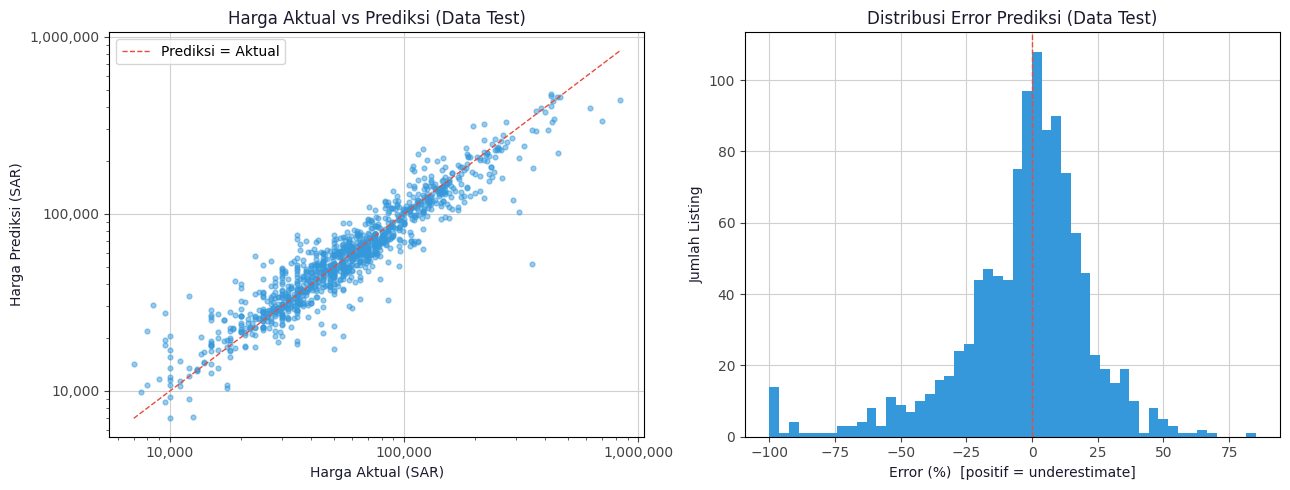

In [91]:
y_pred = pd.Series(final_model.predict(X_test), index=y_test.index)
residual = y_test - y_pred   # positif = underestimate, negatif = overestimate

residual_summary = pd.Series({
    'Mean residual (SAR)': residual.mean(),
    'Median residual (SAR)': residual.median(),
    'Underestimate (%)': (residual > 0).mean() * 100,
    'Overestimate (%)': (residual < 0).mean() * 100,
}).round(1)
display(residual_summary.to_frame('Nilai'))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted
ax = axes[0]
ax.scatter(y_test, y_pred, s=12, alpha=0.5, color=BLUE)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color=RED, linestyle='--', linewidth=1, label='Prediksi = Aktual')
ax.set_xscale('log'); ax.set_yscale('log')
ax.xaxis.set_major_formatter(sar_fmt); ax.yaxis.set_major_formatter(sar_fmt)
ax.set_xlabel('Harga Aktual (SAR)'); ax.set_ylabel('Harga Prediksi (SAR)')
ax.set_title('Harga Aktual vs Prediksi (Data Test)')
ax.legend()

# Distribusi error persentase
ax = axes[1]
pct_error = residual / y_test * 100
ax.hist(pct_error.clip(-100, 100), bins=50, color=BLUE)
ax.axvline(0, color=RED, linestyle='--', linewidth=1)
ax.set_xlabel('Error (%)  [positif = underestimate]')
ax.set_ylabel('Jumlah Listing')
ax.set_title('Distribusi Error Prediksi (Data Test)')

plt.tight_layout()
plt.show()

Residual dihitung sebagai harga aktual dikurangi harga prediksi, sehingga nilai positif berarti model memprediksi lebih rendah dari harga sebenarnya (underestimate) dan nilai negatif berarti model memprediksi lebih tinggi (overestimate).

| Kriteria | Target | Hasil | Status |
|---|---|---|---|
| Proporsi underestimate / overestimate | 45–55% | 51,7% / 48,3% | Tercapai |
| Rata-rata residual | Mendekati 0 | 3.079 SAR | Sedikit positif |

Proporsi underestimate dan overestimate berada dalam rentang 45–55%, sehingga model tidak secara sistematis condong ke salah satu arah. Median residual hanya sekitar 320 SAR, yang menunjukkan bahwa untuk listing pada umumnya, prediksi model sudah seimbang.

Rata-rata residual sebesar 3.079 SAR lebih besar dari median, yang berarti terdapat sejumlah listing dengan harga tinggi yang diprediksi jauh di bawah harga aktualnya. Hal ini merupakan konsekuensi dari transformasi log1p pada target: model dilatih dalam skala log, sehingga prediksi cenderung mendekati nilai tengah harga dan kurang mampu menjangkau harga yang sangat tinggi. Nilai ini relatif kecil, yaitu sekitar 5% dari median harga listing (58.000 SAR), sehingga masih dapat diterima.

Grafik Harga Aktual vs Prediksi menunjukkan bahwa sebagian besar titik berada di sekitar garis diagonal, terutama pada rentang harga sekitar 20.000–300.000 SAR yang mencakup mayoritas listing. Penyimpangan terbesar terjadi di kedua ujung rentang harga. Pada mobil termurah (di bawah sekitar 15.000 SAR), banyak titik berada di atas garis, artinya model cenderung memprediksi lebih mahal dari harga sebenarnya. Sebaliknya, pada mobil termahal (di atas sekitar 500.000 SAR), titik-titik berada di bawah garis, artinya model cenderung memprediksi lebih murah. Pola ini wajar karena jumlah listing di kedua ujung rentang harga sangat sedikit, sehingga model lebih condong memprediksi ke arah harga yang umum.

Distribusi error persentase berpusat di sekitar 0% dengan sebagian besar listing memiliki error dalam rentang ±25%. Namun, sebaran error tidak simetris: ekor kiri (overestimate) jauh lebih panjang dibandingkan ekor kanan, bahkan terdapat belasan listing dengan error mencapai −100% atau lebih, yaitu prediksi dua kali lipat dari harga aktual. Hal ini terjadi karena error persentase untuk underestimate paling besar hanya 100%, sedangkan overestimate tidak memiliki batas atas. Dengan demikian, mobil murah memiliki error persentase tertinggi, sedangkan rata-rata residual yang positif lebih banyak dipengaruhi oleh underestimate pada mobil mahal. Pada 5.3, error dianalisis per segmen harga prediksi, sesuai cara model digunakan pada listing Negotiable.

### **5.3 Error Analysis by Price Segment**

Analisis ini melihat bagaimana besar dan arah error berubah di setiap segmen harga. Segmen dibentuk berdasarkan **harga prediksi**, bukan harga aktual, karena pada listing Negotiable harga aktual tidak tersedia. Dengan begitu, tim pengadaan dapat langsung mengetahui tingkat ketepatan estimasi dari segmen harga yang ditampilkan model.

MAPE dan arah error tetap dihitung terhadap harga aktual pada data test. Error positif berarti nilai prediksi lebih rendah dari harga aktual (underestimate), sedangkan error negatif berarti nilai prediksi lebih tinggi (overestimate).

In [92]:
eval_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
eval_df['Error (%)'] = residual / y_test * 100          # positif = underestimate
eval_df['APE (%)'] = eval_df['Error (%)'].abs()
eval_df['Abs Error (SAR)'] = residual.abs()

PRICE_BINS = [0, 20_000, 50_000, 100_000, 200_000, np.inf]
PRICE_LABELS = ['< 20rb', '20rb–50rb', '50rb–100rb', '100rb–200rb', '≥ 200rb']
eval_df['Segmen Harga'] = pd.cut(eval_df['Predicted'], bins=PRICE_BINS, labels=PRICE_LABELS, right=False)

assert eval_df['Segmen Harga'].notna().all(), "Ada listing yang tidak masuk segmen"
assert len(eval_df) == len(X_test)

segment = (
    eval_df.groupby('Segmen Harga', observed=True)
    .agg(
        Jumlah=('Actual', 'size'),
        MAPE=('APE (%)', 'mean'),
        MAE_SAR=('Abs Error (SAR)', 'mean'),
        Median_Error=('Error (%)', 'median'),
        Underestimate=('Error (%)', lambda s: (s > 0).mean() * 100),
        Total_APE=('APE (%)', 'sum'),
    )
)
segment['Overestimate (%)'] = 100 - segment['Underestimate']
segment['Kontribusi ke MAPE (%)'] = segment.pop('Total_APE') / eval_df['APE (%)'].sum() * 100
segment = segment.rename(columns={
    'MAPE': 'MAPE (%)', 'MAE_SAR': 'MAE (SAR)',
    'Median_Error': 'Median Error (%)', 'Underestimate': 'Underestimate (%)',
})

assert segment['Jumlah'].sum() == len(eval_df)
overall_mape = eval_df['APE (%)'].mean()          # dipakai di 5.4

segment.style.format({
    'Jumlah': '{:,}', 'MAPE (%)': '{:.1f}', 'MAE (SAR)': '{:,.0f}',
    'Median Error (%)': '{:.1f}', 'Underestimate (%)': '{:.1f}',
    'Overestimate (%)': '{:.1f}', 'Kontribusi ke MAPE (%)': '{:.1f}',
})

,Jumlah,MAPE (%),MAE (SAR),Median Error (%),Underestimate (%),Overestimate (%),Kontribusi ke MAPE (%)
Segmen Harga,,,,,,,
< 20rb,59,23.9,"3,791",-2.9,37.3,62.7,7.0
20rb–50rb,398,19.3,"6,138",-0.0,49.7,50.3,38.4
50rb–100rb,399,17.4,"11,647",1.1,53.1,46.9,34.5
100rb–200rb,186,16.1,"23,825",1.7,55.9,44.1,14.9
≥ 200rb,56,18.7,"56,534",2.2,57.1,42.9,5.2


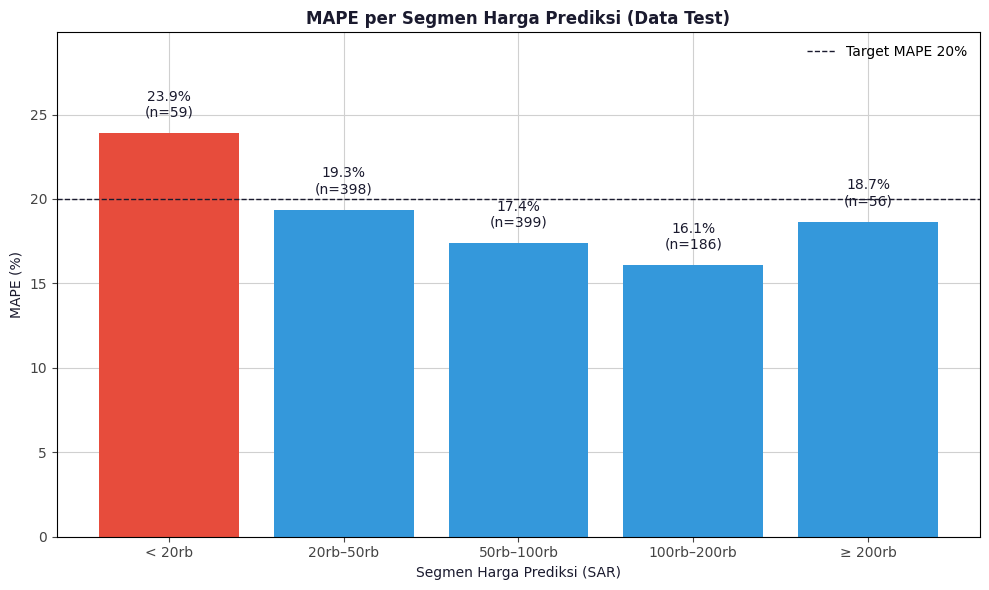

In [93]:
# Visualisasi MAPE per segmen
mape_seg = segment['MAPE (%)']
x = np.arange(len(mape_seg))
colors = [RED if v > 20 else BLUE for v in mape_seg]

fig, ax = plt.subplots(figsize=(10, 6), facecolor='white')
ax.set_facecolor('white')
ax.bar(x, mape_seg, color=colors)

for i, (value, n) in enumerate(zip(mape_seg, segment['Jumlah'])):
    ax.text(i, value + 0.8, f'{value:.1f}%\n(n={n:,})', ha='center', va='bottom',
            color='#1a1a2e', fontsize=10)

ax.axhline(20, color='#1a1a2e', linestyle='--', linewidth=1, label='Target MAPE 20%')
ax.legend(loc='upper right', frameon=False)

ax.set_xticks(x, mape_seg.index, color='#444444')
ax.tick_params(axis='y', colors='#444444')
ax.set_ylim(0, mape_seg.max() * 1.25)
ax.set_xlabel('Segmen Harga Prediksi (SAR)', color='#1a1a2e')
ax.set_ylabel('MAPE (%)', color='#1a1a2e')
ax.set_title('MAPE per Segmen Harga Prediksi (Data Test)', color='#1a1a2e', fontweight='bold')
ax.grid(axis='y', color='#d0d0d0')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Grafik di atas menunjukkan MAPE model pada setiap segmen harga prediksi. Sumbu X adalah segmen harga prediksi dalam SAR, dan sumbu Y adalah MAPE dalam persen. Garis putus-putus menandai target MAPE 20%. Segmen berwarna merah menandakan MAPE di atas target, dan angka n adalah jumlah listing pada segmen tersebut.

Segmen dibentuk berdasarkan harga prediksi karena pada listing Negotiable harga aktual tidak tersedia, sehingga tim pengadaan hanya bisa melihat segmen dari nilai prediksi. Kolom **Median Error** menunjukkan arah error yang umum di setiap segmen (positif berarti underestimate, negatif berarti overestimate), sedangkan **Kontribusi ke MAPE** menunjukkan seberapa besar segmen tersebut menyumbang ke total error persentase pada data test.

Empat dari lima segmen memenuhi target MAPE 20%. Segmen 20rb–200rb SAR mencakup 983 listing (sekitar 90% data test) dengan MAPE antara 16,1% dan 19,3%. Segmen 100rb–200rb menjadi yang paling tepat dengan MAPE 16,1%.

| Segmen | Temuan |
|---|---|
| < 20rb SAR | Satu-satunya segmen yang melewati target, dengan MAPE 23,9%. Median error −2,9% dan 62,7% listing di-overestimate, artinya nilai prediksi cenderung sedikit lebih tinggi dari harga sebenarnya. Segmen ini hanya mencakup 5,4% data test dan menyumbang 7,0% dari total error persentase. Karena harganya kecil, selisih beberapa ribu SAR saja sudah menghasilkan persentase error yang besar. |
| ≥ 200rb SAR | MAPE 18,7%, masih di bawah target. Median error +2,2% dan 57,1% listing di-underestimate, artinya nilai prediksi cenderung sedikit lebih rendah untuk mobil mahal. Segmen ini memiliki listing paling sedikit, yaitu 56 listing (5,1% data test). |

Penyumbang error terbesar secara keseluruhan adalah segmen 20rb–50rb (38,4%) dan 50rb–100rb (34,5%). Ini bukan karena error-nya tinggi, tetapi karena kedua segmen ini mencakup sekitar 72% data test.

Dari sisi arah error, proporsi underestimate naik secara bertahap dari 37,3% di segmen termurah menjadi 57,1% di segmen termahal. Namun, median error di semua segmen berada di kisaran −2,9% sampai +2,2%, sehingga nilai prediksi relatif seimbang dan tidak condong kuat ke satu arah di segmen mana pun.

Dari sisi bisnis, estimasi model pada segmen 20.000 SAR ke atas dapat langsung dipakai sebagai acuan awal penawaran karena MAPE-nya di bawah target. Untuk mobil dengan nilai prediksi di bawah 20.000 SAR, estimasi perlu dicek ulang secara manual sebelum penawaran diajukan, karena error rata-ratanya sekitar 24% dan sebagian besar nilai prediksinya lebih tinggi dari harga aktual, sehingga berisiko membuat Syarah membeli di atas harga pasar.

### **5.4 Largest Errors and Rare Categories**

In [94]:
# Gabungkan hasil prediksi dengan fitur aslinya
eval_full = eval_df.join(X_test[['Make', 'Type', 'Year', 'Mileage', 'Options']])
assert len(eval_full) == len(eval_df)

# 1. Sepuluh listing dengan error persentase terbesar
top_errors = eval_full.nlargest(10, 'APE (%)')[
    ['Make', 'Type', 'Year', 'Mileage', 'Options', 'Actual', 'Predicted', 'Error (%)']
]
# Nilai Mileage yang benar-benar dilihat model (setelah imputasi di pipeline)
fitted_imputer = final_model.regressor_.named_steps['preprocessor'].named_steps['imputer']
X_test_imputed = fitted_imputer.transform(X_test)
assert X_test_imputed['Mileage'].isna().sum() == 0

top_errors['Mileage (imputed)'] = X_test_imputed.loc[top_errors.index, 'Mileage']

# Bandingkan performa listing dengan dan tanpa Mileage
mileage_missing = X_test['Mileage'].isna().map({True: 'Kosong (diimputasi)', False: 'Terisi'})
mileage_summary = (
    eval_full.groupby(mileage_missing)
    .agg(Jumlah=('Actual', 'size'), MAPE=('APE (%)', 'mean'), Median_Error=('Error (%)', 'median'))
    .rename(columns={'MAPE': 'MAPE (%)', 'Median_Error': 'Median Error (%)'})
)
mileage_summary.index.name = 'Mileage'

display(top_errors.style.format({
    'Mileage': '{:,.0f}', 'Mileage (imputed)': '{:,.0f}', 'Actual': '{:,.0f}',
    'Predicted': '{:,.0f}', 'Error (%)': '{:+.1f}',
}, na_rep='kosong'))
display(mileage_summary.style.format({'MAPE (%)': '{:.1f}', 'Median Error (%)': '{:+.1f}'}))

,Make,Type,Year,Mileage,Options,Actual,Predicted,Error (%),Mileage (imputed)
4402,Fiat,Other,2013,"180,000",Standard,"8,500","30,607",-260.1,"180,000"
3011,Toyota,Corolla,2001,kosong,Standard,"9,500","27,501",-189.5,"350,000"
37,Toyota,Land Cruiser,1993,kosong,Semi Full,"12,000","34,434",-187.0,"196,671"
3128,Chevrolet,Blazer,2007,kosong,Semi Full,"8,000","21,908",-173.9,"280,000"
4675,MG,6,2014,"79,000",Full,"23,000","57,590",-150.4,"79,000"
4535,Audi,A8,2007,"180,000",Full,"19,000","41,634",-119.1,"180,000"
4769,Toyota,Corolla,2016,kosong,Standard,"35,000","75,694",-116.3,"117,000"
2527,Ford,Expedition,2013,"21,700",Standard,"35,000","72,500",-107.1,"21,700"
2818,Ford,Echo Sport,2016,"217,000",Standard,"25,000","51,546",-106.2,"217,000"
724,Mercedes,SEL,1995,"252,611",Semi Full,"10,000","20,518",-105.2,"252,611"


,Jumlah,MAPE (%),Median Error (%)
Mileage,,,
Kosong (diimputasi),85,28.6,-6.9
Terisi,1013,17.4,+1.1


Kesepuluh listing dengan error terbesar seluruhnya merupakan overestimate, yaitu model memprediksi harga jauh lebih tinggi dari harga listing. Harga listing tertingginya 35.000 SAR, dan delapan di antaranya berharga 25.000 SAR ke bawah, sesuai dengan temuan pada 5.3 bahwa error persentase terbesar terjadi pada mobil murah.

Beberapa listing memiliki harga yang tampak tidak sesuai dengan spesifikasinya, misalnya Toyota Corolla tahun 2016 seharga 35.000 SAR atau Audi A8 tahun 2007 seharga 19.000 SAR. Kemungkinan penyebabnya adalah kondisi mobil yang buruk (misalnya bekas kecelakaan) atau kesalahan input harga, namun hal ini tidak dapat dipastikan dari data. Informasi kondisi mobil tidak tersedia pada dataset, sehingga model memprediksi harga berdasarkan spesifikasi mobil dalam kondisi wajar. Error pada listing seperti ini lebih mencerminkan keterbatasan data dibandingkan kesalahan model.

Empat dari sepuluh listing tersebut tidak mencantumkan `Mileage`. Secara keseluruhan, listing dengan `Mileage` kosong (85 listing) memiliki MAPE 28,6%, jauh lebih tinggi dibandingkan listing dengan `Mileage` terisi yang memiliki MAPE 17,4%. Median error-nya juga negatif (−6,9%), yang berarti model cenderung memprediksi lebih mahal. Imputasi mengisi nilai kosong dengan median jarak tempuh mobil seumur, sehingga mobil tersebut diperlakukan seolah-olah kondisinya rata-rata. Padahal, listing yang tidak mencantumkan jarak tempuh kemungkinan lebih sering merupakan mobil dengan jarak tempuh tinggi atau kondisi kurang baik.

In [95]:
# 2. Performa berdasarkan frekuensi kategori di data train
def frequency_segment(col, bins, labels):
    """Merangkum performa model berdasarkan seberapa sering kategori muncul di data train.

    Args:
        col: Nama kolom kategorikal (misalnya 'Make' atau 'Type').
        bins: Batas jumlah kemunculan di data train.
        labels: Label untuk setiap rentang.

    Returns:
        DataFrame berisi jumlah listing, MAPE, dan median error per kelompok frekuensi.
    """
    train_counts = X_train[col].value_counts()
    freq = eval_full[col].map(train_counts).fillna(0)
    group = pd.cut(freq, bins=bins, labels=labels, right=False)
    assert group.notna().all(), f"{col}: ada listing yang tidak masuk kelompok"

    summary = (
        eval_full.groupby(group, observed=True)
        .agg(Jumlah=('Actual', 'size'), MAPE=('APE (%)', 'mean'), Median_Error=('Error (%)', 'median'))
        .rename(columns={'MAPE': 'MAPE (%)', 'Median_Error': 'Median Error (%)'})
    )
    summary.index.name = f'Frekuensi {col} di Train'
    return summary


make_freq = frequency_segment(
    'Make', bins=[0, 1, 10, 50, 200, np.inf],
    labels=['Tidak ada', '1–9', '10–49', '50–199', '≥ 200'],
)
type_freq = frequency_segment(
    'Type', bins=[0, 1, 5, 20, 50, np.inf],
    labels=['Tidak ada', '1–4', '5–19', '20–49', '≥ 50'],
)

fmt = {'MAPE (%)': '{:.1f}', 'Median Error (%)': '{:+.1f}'}
display(make_freq.style.format(fmt))
display(type_freq.style.format(fmt))


,Jumlah,MAPE (%),Median Error (%)
Frekuensi Make di Train,,,
Tidak ada,1,34.2,-34.2
1–9,25,33.1,+4.7
10–49,93,29.4,-7.0
50–199,298,18.3,-0.5
≥ 200,681,16.2,+1.5


,Jumlah,MAPE (%),Median Error (%)
Frekuensi Type di Train,,,
Tidak ada,31,34.1,+4.6
1–4,85,26.6,-3.8
5–19,173,24.7,-5.9
20–49,306,16.6,+2.4
≥ 50,503,14.7,+1.2


Untuk mengukur pengaruh kategori yang jarang muncul, setiap listing pada data test dikelompokkan berdasarkan berapa kali `Make` dan `Type`-nya muncul pada data train. Hal ini relevan karena target encoding menghitung rata-rata harga per kategori dari data train, sehingga kategori dengan sedikit contoh memiliki nilai encoding yang kurang dapat diandalkan.

| Frekuensi di Data Train | Make | Type |
|---|---|---|
| Sering muncul | MAPE 16,2% (≥ 200 kali, 681 listing) | MAPE 14,7% (≥ 50 kali, 503 listing) |
| Jarang muncul | MAPE 29,4%–33,1% (1–49 kali, 118 listing) | MAPE 24,7%–26,6% (1–19 kali, 258 listing) |
| Tidak ada di data train | MAPE 34,2% (1 listing) | MAPE 34,1% (31 listing) |

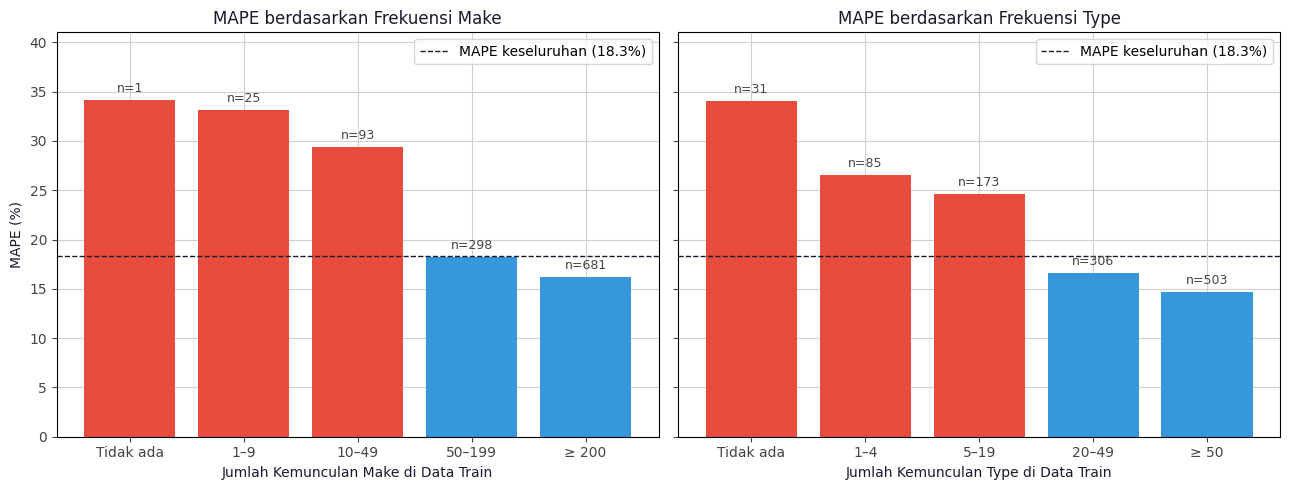

In [96]:
# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (summary, title) in zip(axes, [(make_freq, 'Make'), (type_freq, 'Type')]):
    colors = [RED if v > overall_mape else BLUE for v in summary['MAPE (%)']]
    bars = ax.bar(summary.index.astype(str), summary['MAPE (%)'], color=colors)
    for bar, n in zip(bars, summary['Jumlah']):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
                f'n={n}', ha='center', fontsize=9, color='#444444')
    ax.axhline(overall_mape, color='#1a1a2e', linestyle='--', linewidth=1,
               label=f'MAPE keseluruhan ({overall_mape:.1f}%)')
    ax.set_xlabel(f'Jumlah Kemunculan {title} di Data Train')
    ax.set_title(f'MAPE berdasarkan Frekuensi {title}')
    ax.legend(loc='upper right')

axes[0].set_ylabel('MAPE (%)')
axes[0].set_ylim(0, max(make_freq['MAPE (%)'].max(), type_freq['MAPE (%)'].max()) * 1.2)
plt.tight_layout()
plt.show()

Kedua grafik menunjukkan pola yang konsisten: semakin jarang sebuah merek atau model mobil muncul di data train, semakin tinggi error prediksinya. Pada `Type`, MAPE naik bertahap dari 14,7% untuk model yang muncul minimal 50 kali hingga 34,1% untuk model yang tidak pernah muncul di data train. Model mobil yang muncul kurang dari 20 kali mencakup 289 listing atau sekitar 26% data test, dan seluruh kelompok ini memiliki MAPE di atas 24%. Pola yang sama terlihat pada `Make`, di mana merek yang muncul kurang dari 50 kali memiliki MAPE di atas 29%.

Temuan ini menunjukkan bahwa keterbatasan utama model terletak pada ketersediaan data per merek dan model. Model mobil yang muncul kurang dari 20 kali memiliki MAPE di atas 24%, lebih tinggi dibandingkan segmen harga mana pun pada 5.3. Prediksi untuk merek dan model populer seperti Toyota atau Hyundai jauh lebih dapat diandalkan dibandingkan merek langka atau model yang jarang dijual di Syarah.com. Untuk pengembangan berikutnya, penambahan data listing pada merek dan model yang jarang muncul akan membantu meningkatkan akurasi pada kelompok ini.

## **Section 6. Model Interpretation**

### **6.1 Feature Importance**

,Feature,Importance
0,Car_Age,0.274615
1,Type,0.209726
2,Engine_Size,0.107495
3,Options,0.100166
4,Mileage,0.075062
5,Make,0.074403
6,Gear_Type_Manual,0.045269
7,Fuel_Type_Gas,0.044245
8,Origin_Saudi,0.023142
9,Origin_Other,0.019642


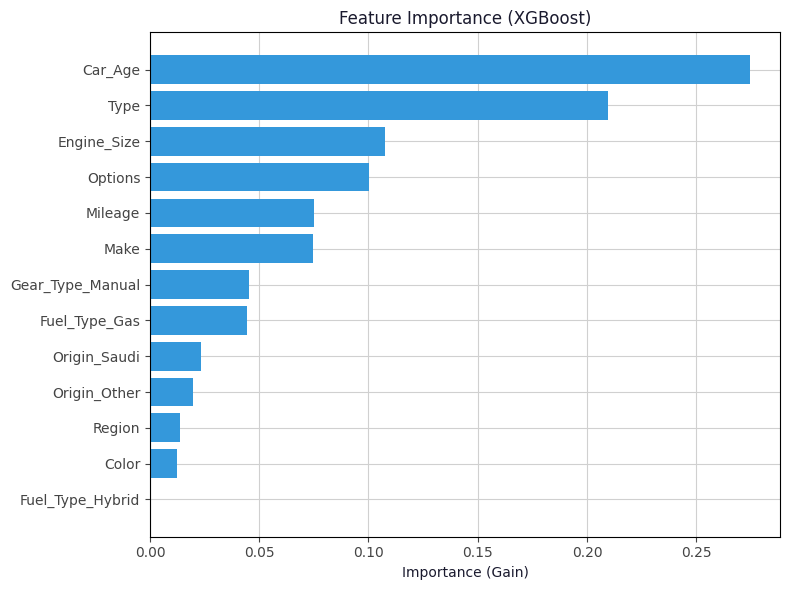

In [97]:
xgb_model = final_model.regressor_.named_steps['model']
preprocessor = final_model.regressor_.named_steps['preprocessor']
feature_names = [name.split('__')[-1] for name in preprocessor.get_feature_names_out()]

feature_importance_df = (
    pd.DataFrame({'Feature': feature_names, 'Importance': xgb_model.feature_importances_})
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_df)

assert len(feature_importance_df) == xgb_model.n_features_in_
assert np.isclose(feature_importance_df['Importance'].sum(), 1.0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color=BLUE)
ax.invert_yaxis()
ax.set_xlabel('Importance (Gain)')
ax.set_title('Feature Importance (XGBoost)')

plt.tight_layout()
plt.show()

`Car_Age` menjadi fitur paling berpengaruh dengan importance 0,275, diikuti `Type` dengan 0,210. Kedua fitur ini menyumbang hampir setengah (48%) dari total importance, yang menunjukkan bahwa harga mobil bekas terutama ditentukan oleh umur mobil dan model mobilnya. Hal ini sejalan dengan temuan pada tahap EDA, di mana harga menurun seiring bertambahnya umur mobil dan sangat bervariasi antar model.

Kelompok berikutnya adalah `Engine_Size` (0,107) dan `Options` (0,100), disusul `Mileage` (0,075) dan `Make` (0,074). Enam fitur teratas ini secara total menyumbang sekitar 84% dari importance model. Importance `Make` lebih kecil dibandingkan `Type` karena informasi merek sebagian besar sudah terkandung dalam model mobil. Misalnya, model Camry sudah pasti bermerek Toyota, sehingga model lebih sering menggunakan `Type` yang lebih spesifik.

Fitur kategorikal dengan sedikit kategori memiliki pengaruh yang lebih kecil, yaitu `Gear_Type` (0,045), `Fuel_Type` (0,044), dan `Origin` (0,043 jika kedua kolomnya dijumlahkan). `Region` (0,014) dan `Color` (0,012) memiliki importance terendah, yang menunjukkan bahwa lokasi penjualan dan warna mobil hampir tidak memengaruhi harga. Sementara itu, `Fuel_Type_Hybrid` bernilai 0, artinya kolom ini sama sekali tidak pernah digunakan model untuk memecah data.

Perlu dicatat bahwa metode ini hanya menunjukkan seberapa besar peran sebuah fitur, tanpa menunjukkan arah pengaruhnya terhadap harga. Arah pengaruh tersebut dianalisis menggunakan SHAP pada bagian berikutnya.

### **6.2 SHAP Analysis**

Harga dasar (base value): 59,196 SAR


,Feature,Mean |SHAP|,Perkiraan Dampak Harga (%)
0,Car_Age,0.301,35.1
1,Type,0.218,24.4
2,Engine_Size,0.164,17.8
3,Make,0.104,10.9
4,Mileage,0.101,10.7
5,Options,0.059,6.1
6,Region,0.017,1.7
7,Color,0.013,1.3
8,Origin_Saudi,0.007,0.7
9,Fuel_Type_Gas,0.006,0.6


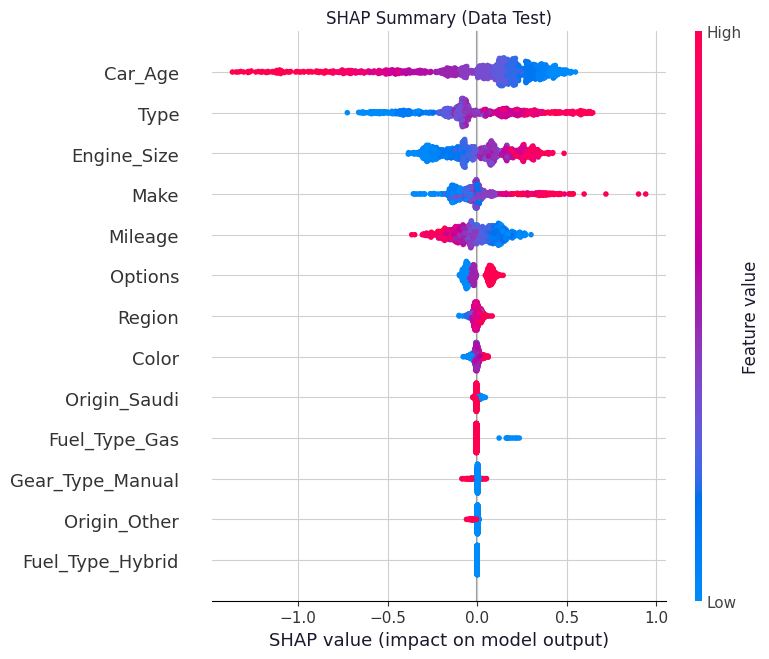

In [98]:
# Data test setelah preprocessing, yaitu input yang benar-benar dilihat XGBoost
X_test_transformed = pd.DataFrame(
    np.asarray(preprocessor.transform(X_test)),
    columns=feature_names,
    index=X_test.index,
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_transformed)

# Validasi: base value + total SHAP harus sama dengan prediksi model (dalam skala log)
log_pred = np.log1p(final_model.predict(X_test))   # prediksi model final, dikembalikan ke skala log
assert shap_values.values.shape == X_test_transformed.shape
assert np.allclose(shap_values.base_values + shap_values.values.sum(axis=1), log_pred, atol=1e-3)

# Ringkasan dampak rata-rata tiap fitur, dikonversi ke persen perubahan harga
shap_summary = (
    pd.DataFrame({
        'Feature': feature_names,
        'Mean |SHAP|': np.abs(shap_values.values).mean(axis=0),
    })
    .assign(**{'Perkiraan Dampak Harga (%)': lambda d: np.expm1(d['Mean |SHAP|']) * 100})
    .sort_values('Mean |SHAP|', ascending=False)
    .reset_index(drop=True)
)
print(f"Harga dasar (base value): {np.expm1(shap_values.base_values[0]):,.0f} SAR")
display(shap_summary.style.format({'Mean |SHAP|': '{:.3f}', 'Perkiraan Dampak Harga (%)': '{:.1f}'}))

shap.plots.beeswarm(shap_values, max_display=len(feature_names), show=False)
plt.title('SHAP Summary (Data Test)')
plt.tight_layout()
plt.show()

SHAP (SHapley Additive exPlanations) menjelaskan kontribusi setiap fitur terhadap prediksi untuk setiap listing. Prediksi model dimulai dari harga dasar (base value), yaitu sekitar 59.196 SAR, kemudian setiap fitur menaikkan atau menurunkan harga tersebut. Karena model dilatih dengan target log1p, nilai SHAP berada dalam skala log, sehingga dapat dibaca sebagai perubahan harga dalam persen. Sebagai contoh, nilai SHAP +0,5 berarti fitur tersebut menaikkan harga prediksi sekitar 65%, sedangkan −0,5 berarti menurunkannya sekitar 39%.

Pada beeswarm plot, setiap titik mewakili satu listing pada data test. Posisi horizontal menunjukkan arah dan besar pengaruh terhadap harga, sedangkan warna menunjukkan nilai fitur (merah berarti tinggi, biru berarti rendah). Untuk `Make`, `Type`, `Region`, dan `Color`, nilai tinggi berarti kategori dengan rata-rata harga tinggi, karena fitur ini telah diubah menggunakan target encoding.

| Fitur | Rata-rata Dampak | Arah Pengaruh |
|---|---|---|
| `Car_Age` | ±35% | Mobil yang lebih tua (merah) menurunkan harga hingga sekitar 70%, sedangkan mobil yang lebih baru (biru) menaikkan harga hingga sekitar 70%. |
| `Type` | ±24% | Model mobil dengan rata-rata harga tinggi menaikkan harga hingga sekitar 90%, sedangkan model murah menurunkannya hingga sekitar 50%. |
| `Engine_Size` | ±18% | Mesin yang lebih besar menaikkan harga, mesin yang lebih kecil menurunkannya. |
| `Make` | ±11% | Sebagian besar listing terpengaruh kecil, tetapi merek premium dapat menaikkan harga lebih dari dua kali lipat, terlihat dari titik merah yang menjauh ke kanan. |
| `Mileage` | ±11% | Jarak tempuh tinggi menurunkan harga, jarak tempuh rendah menaikkannya. |
| `Options` | ±6% | Kelengkapan Full menaikkan harga dan Standard menurunkannya, dengan pemisahan yang sangat jelas. |

Arah pengaruh seluruh fitur utama sesuai dengan logika pasar mobil bekas dan temuan pada tahap EDA: mobil yang lebih baru, bermerek dan bermodel mahal, bermesin besar, berjarak tempuh rendah, serta memiliki kelengkapan penuh dihargai lebih tinggi. Hal ini menunjukkan bahwa model mempelajari pola yang masuk akal, bukan menghafal data.

Fitur lainnya memiliki dampak rata-rata di bawah 2%. `Region` dan `Color` hanya sedikit menggeser harga, sedangkan `Origin`, `Gear_Type`, dan `Fuel_Type` hampir tidak berpengaruh untuk sebagian besar listing. Pengecualian terlihat pada `Fuel_Type_Gas`, di mana sebagian kecil listing yang bukan berbahan bakar bensin (titik biru) mendapat kenaikan harga sekitar 20%.

Urutan fitur berdasarkan SHAP sejalan dengan feature importance pada 6.1. `Car_Age` dan `Type` tetap menjadi dua fitur paling berpengaruh. Perbedaannya, `Make` naik ke posisi keempat dan `Options` turun ke posisi keenam. Hal ini terjadi karena kedua metode mengukur hal yang berbeda: gain mengukur seberapa besar penurunan error saat fitur digunakan untuk memecah data, sedangkan SHAP mengukur seberapa besar fitur tersebut mengubah nilai prediksi. `Options` hanya memiliki tiga nilai sehingga efektif memisahkan data, tetapi dampaknya terhadap harga relatif kecil. Sebaliknya, `Make` memiliki dampak yang sangat besar pada sebagian kecil listing bermerek premium.

## **Section 7. Inference on Negotiable Listings**

### **7.1 Load and Validate Data**

In [99]:
df_nego = pd.read_csv('../data/processed/cars_negotiable.csv')

assert df_nego.shape == (2577, 11), f"Shape tidak sesuai: {df_nego.shape}"
assert set(FEATURES) == set(df_nego.columns), "Kolom tidak sama dengan fitur training"

X_nego = df_nego[FEATURES]   # urutan kolom disamakan dengan data training

missing = pd.DataFrame({
    'Train (%)': X_train.isna().mean() * 100,
    'Negotiable (%)': X_nego.isna().mean() * 100,
}).query('`Train (%)` > 0 or `Negotiable (%)` > 0')

print(f"Negotiable: {X_nego.shape}")
missing.style.format('{:.1f}')

Negotiable: (2577, 11)


,Train (%),Negotiable (%)
Mileage,6.9,17.7
Engine_Size,21.8,40.1
Options,0.7,2.6
Origin,0.5,2.6
Gear_Type,0.4,2.1


Data inferensi berisi **2.577 listing** berstatus Negotiable dengan 11 fitur yang sama seperti data training. Nilai kosong dan kolom `Year` tidak perlu diproses secara manual, karena seluruh tahapan imputasi, konversi `Car_Age`, dan encoding sudah tercakup di dalam pipeline model final.

Proporsi nilai kosong pada data Negotiable jauh lebih tinggi dibandingkan data train. `Mileage` kosong pada 17,7% listing (train 6,9%) dan `Engine_Size` kosong pada 40,1% listing (train 21,8%). Hal ini menunjukkan bahwa penjual yang tidak mencantumkan harga juga cenderung tidak melengkapi informasi mobilnya. Berdasarkan temuan pada 5.4, listing dengan `Mileage` kosong memiliki MAPE yang jauh lebih tinggi (28,6% vs 17,4%), sehingga akurasi prediksi pada data Negotiable kemungkinan lebih rendah dibandingkan hasil evaluasi pada data test.

### **7.2 Unseen and Rare Categories**

In [100]:
CATEGORICAL_FEATURES = ORD_FEATURES + LOW_CARD_FEATURES + HIGH_CARD_FEATURES

unseen = pd.DataFrame({
    col: {
        'Kategori Baru': len(set(X_nego[col].dropna()) - set(X_train[col].dropna())),
        'Listing Terdampak': (~X_nego[col].isin(X_train[col]) & X_nego[col].notna()).sum(),
    }
    for col in CATEGORICAL_FEATURES
}).T

unseen['Listing Terdampak (%)'] = unseen['Listing Terdampak'] / len(X_nego) * 100
unseen.style.format({'Listing Terdampak (%)': '{:.1f}'})

,Kategori Baru,Listing Terdampak,Listing Terdampak (%)
Options,0,0,0.0
Origin,0,0,0.0
Fuel_Type,0,0,0.0
Gear_Type,0,0,0.0
Make,4,5,0.2
Type,53,69,2.7
Region,0,0,0.0
Color,0,0,0.0


Seluruh kategori pada fitur dengan sedikit kategori (`Options`, `Origin`, `Fuel_Type`, `Gear_Type`) serta `Region` dan `Color` sudah tercakup di data train. Kategori baru hanya ditemukan pada `Make` (4 merek, 5 listing) dan `Type` (53 model, 69 listing atau 2,7% data). Pipeline tetap dapat memproses listing ini tanpa error, karena target encoding menggantikan kategori yang tidak dikenal dengan rata-rata global. Namun, prediksi untuk listing ini kurang dapat diandalkan, karena pada 5.4 model mobil yang tidak muncul di data train menghasilkan MAPE sekitar 34%.

### **7.3 Price Prediction**

In [101]:
nego_result = X_nego.copy()
nego_result['Predicted_Price'] = final_model.predict(X_nego)

assert len(nego_result) == len(df_nego)
assert nego_result['Predicted_Price'].notna().all(), "Ada prediksi NaN"
assert (nego_result['Predicted_Price'] > 0).all(), "Ada prediksi harga negatif atau nol"

nego_result[['Make', 'Type', 'Year', 'Mileage', 'Predicted_Price']].head().style.format(
    {'Mileage': '{:,.0f}', 'Predicted_Price': '{:,.0f}'}, na_rep='kosong'
)

,Make,Type,Year,Mileage,Predicted_Price
0,Nissan,Patrol,2016,"5,448","135,450"
1,GMC,Yukon,2009,"323,000","42,943"
2,GMC,Yukon,2018,"37,000","171,402"
3,Toyota,Camry,2019,"8,000","92,053"
4,Toyota,Avalon,2008,"169,000","41,380"


Harga setiap listing Negotiable diprediksi menggunakan model final, yang secara otomatis mengembalikan hasil dalam satuan SAR. Seluruh 2.577 listing berhasil diprediksi tanpa nilai kosong maupun harga negatif atau nol.

Hasil prediksi ini digunakan sebagai acuan awal penawaran, bukan harga beli final. Berdasarkan temuan pada Section 5, estimasi perlu dicek ulang secara manual untuk listing dengan harga prediksi di bawah 20.000 SAR (MAPE 23,9% pada 5.3), `Type` yang jarang muncul di data train (MAPE di atas 24% pada 5.4), dan `Mileage` yang kosong (MAPE 28,6% pada 5.4).

### **7.4 Prediction Distribution Check**

,Harga Listing (Train),Prediksi (Negotiable)
mean,"80,270","66,499"
std,"76,514","58,283"
min,"5,000","7,569"
25%,"36,500","29,684"
50%,"59,000","51,069"
75%,"95,000","81,380"
max,"1,150,000","483,801"


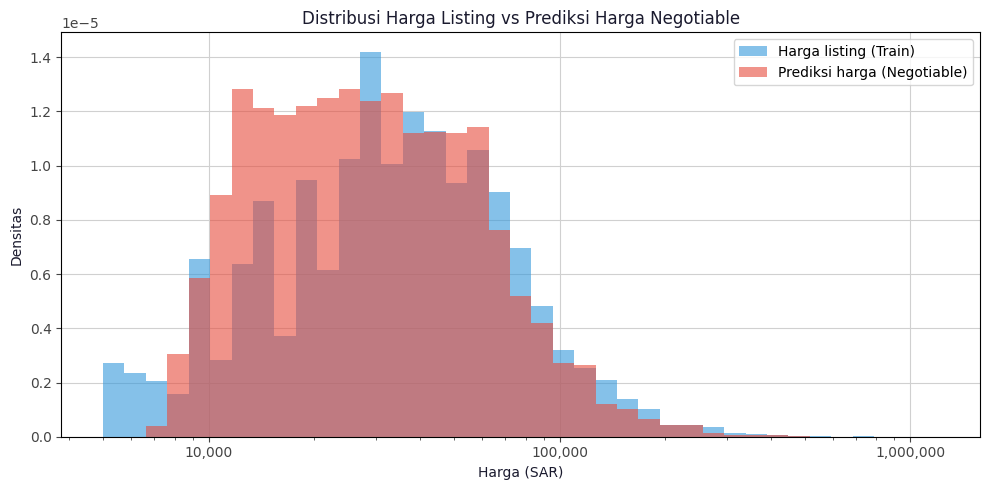

In [102]:
compare = pd.DataFrame({
    'Harga Listing (Train)': y_train.describe(percentiles=[.25, .5, .75]),
    'Prediksi (Negotiable)': nego_result['Predicted_Price'].describe(percentiles=[.25, .5, .75]),
}).drop('count')
display(compare.style.format('{:,.0f}'))

bins = np.logspace(np.log10(5_000), np.log10(1_200_000), 40)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(y_train, bins=bins, density=True, alpha=0.6, color=BLUE, label='Harga listing (Train)')
ax.hist(nego_result['Predicted_Price'], bins=bins, density=True, alpha=0.6, color=RED,
        label='Prediksi harga (Negotiable)')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(sar_fmt)
ax.set_xlabel('Harga (SAR)')
ax.set_ylabel('Densitas')
ax.set_title('Distribusi Harga Listing vs Prediksi Harga Negotiable')
ax.legend()

plt.tight_layout()
plt.show()

In [103]:
profile = pd.DataFrame({
    'Train': [(REFERENCE_YEAR - X_train['Year']).median(), X_train['Mileage'].median()],
    'Negotiable': [(REFERENCE_YEAR - X_nego['Year']).median(), X_nego['Mileage'].median()],
}, index=['Median Car_Age (tahun)', 'Median Mileage (km)'])
profile.style.format('{:,.0f}')

,Train,Negotiable
Median Car_Age (tahun),5,7
Median Mileage (km),"109,000","144,790"


Karena harga aktual listing Negotiable tidak diketahui, akurasi prediksi tidak dapat diukur secara langsung. Sebagai gantinya, dilakukan pengecekan kewajaran prediksi dengan membandingkan distribusi harga prediksi Negotiable dengan distribusi harga listing pada data train.

| Statistik | Harga Listing (Train) | Prediksi (Negotiable) |
|---|---|---|
| Kuartil 1 | 36.500 SAR | 29.684 SAR |
| Median | 59.000 SAR | 51.069 SAR |
| Kuartil 3 | 95.000 SAR | 81.380 SAR |
| Rentang | 5.000–1.150.000 SAR | 7.569–483.801 SAR |

Seluruh prediksi berada dalam rentang harga pasar yang wajar, tanpa nilai negatif atau nilai yang tidak masuk akal, dan bentuk distribusinya serupa dengan harga listing pada data train. Hal ini menunjukkan bahwa model memproses data Negotiable dengan benar.

Terdapat dua perbedaan utama. Pertama, prediksi harga Negotiable cenderung lebih rendah, dengan median sekitar 13% di bawah median harga listing pada data train dan konsentrasi yang lebih tinggi pada rentang 12.000–30.000 SAR. Perbedaan ini sejalan dengan profil mobil Negotiable yang lebih tua dan lebih banyak dipakai, dengan median umur 7 tahun dan median jarak tempuh sekitar 144.790 km, dibandingkan data train dengan median umur 5 tahun dan median jarak tempuh 109.000 km. Oleh karena itu, harga prediksi yang lebih rendah merupakan hal yang wajar dan bukan indikasi kesalahan model.

Kedua, rentang prediksi lebih sempit, yaitu tidak ada prediksi di bawah sekitar 7.500 SAR maupun di atas sekitar 484.000 SAR. Hal ini sesuai dengan temuan pada 5.2, di mana model cenderung menarik prediksi ke arah harga yang umum, sehingga mobil termurah diprediksi lebih mahal dan mobil termahal diprediksi lebih murah. Dengan demikian, estimasi harga untuk mobil Negotiable yang sangat mahal kemungkinan berada di bawah harga pasar sebenarnya, sehingga penawaran untuk mobil di segmen ini perlu disesuaikan agar tidak ditolak penjual.

## **Section 8. Save Model**

### **8.1 Save Model**

In [104]:
# Pastikan model merujuk ke car_preprocessing, bukan __main__, agar bisa di-load di luar notebook
assert GroupMedianImputer.__module__ == 'car_preprocessing', "GroupMedianImputer masih didefinisikan di notebook"
assert add_car_age.__module__ == 'car_preprocessing', "add_car_age masih didefinisikan di notebook"

MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / 'used_car_price_model.pkl'

artifact = {
    'model': final_model,
    'features': FEATURES,
    'categories': {col: sorted(X_train[col].dropna().unique()) for col in CATEGORICAL_FEATURES},
    'make_to_type': X_train.groupby('Make')['Type'].apply(lambda s: sorted(s.unique())).to_dict(),
    'year_range': (int(X_train['Year'].min()), int(X_train['Year'].max())),
    'test_metrics': test_results.query("Data == 'Test'").iloc[0].drop(['Model', 'Data']).to_dict(),
    'versions': {
        'python': sys.version.split()[0],
        'scikit-learn': sklearn.__version__,
        'xgboost': xgboost.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__,
    },
}

joblib.dump(artifact, MODEL_PATH)
print(f"Model disimpan di {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("Versi library:", artifact['versions'])

Model disimpan di ..\models\used_car_price_model.pkl (2.0 MB)
Versi library: {'python': '3.13.12', 'scikit-learn': '1.8.0', 'xgboost': '3.3.0', 'pandas': '2.3.3', 'numpy': '2.4.5'}


Model final disimpan dalam satu file `used_car_price_model.pkl` menggunakan `joblib`. Selain model, file ini juga menyimpan informasi pendukung yang dibutuhkan saat model digunakan di aplikasi Streamlit:

| Komponen | Kegunaan |
|---|---|
| `model` | Pipeline lengkap (preprocessing dan XGBoost) untuk menghasilkan prediksi harga dalam SAR |
| `features` | Urutan kolom input, agar sama dengan saat training |
| `categories` | Daftar kategori dari data train untuk pilihan dropdown, seperti `Make`, `Region`, dan `Color` |
| `make_to_type` | Daftar model mobil per merek, agar pilihan `Type` menyesuaikan `Make` yang dipilih |
| `year_range` | Rentang tahun produksi pada data train sebagai batas input |
| `test_metrics` | Performa model pada data test sebagai informasi tingkat akurasi |
| `versions` | Versi library yang digunakan saat training |

Fungsi dan class custom (`add_car_age`, `car_age_feature_names`, dan `GroupMedianImputer`) disimpan di `src/car_preprocessing.py` dan diimport ke notebook, sehingga model dapat di-load di luar notebook dengan menyertakan file tersebut. Versi library juga dicatat, karena model scikit-learn dan XGBoost hanya dijamin dapat dibuka dengan versi library yang sama.

### **8.2 Load Verification**

In [105]:
loaded = joblib.load(MODEL_PATH)
loaded_model = loaded['model']

# Pastikan model hasil load identik dengan model di notebook
assert set(loaded) == set(artifact), "Isi file tidak lengkap"
assert np.allclose(loaded_model.predict(X_test), final_model.predict(X_test)), \
    "Prediksi model hasil load berbeda dengan model di notebook"

# Contoh prediksi untuk satu listing
sample = X_test.iloc[[0]]
pred_price = loaded_model.predict(sample)[0]   # sudah dalam SAR, tidak perlu expm1

print("Contoh input:")
display(sample)
print(f"\nPrediksi harga: {pred_price:,.0f} SAR")
print(f"Harga aktual  : {y_test.iloc[0]:,.0f} SAR")
print(f"Selisih       : {abs(pred_price - y_test.iloc[0]) / y_test.iloc[0]:.1%}")

Contoh input:


,Year,Mileage,Engine_Size,Options,Origin,Fuel_Type,Gear_Type,Make,Type,Region,Color
1468,2017,103503.0,2.5,Full,Saudi,Gas,Automatic,Renault,Koleos,Riyadh,Black



Prediksi harga: 46,731 SAR
Harga aktual  : 64,000 SAR
Selisih       : 27.0%


Model yang telah disimpan kemudian di-load kembali untuk memastikan file tersimpan dengan benar. Seluruh komponen tersedia, dan prediksi model hasil load identik dengan model di notebook pada seluruh 1.098 listing data test.

Sebagai contoh, Renault Koleos tahun 2017 dengan jarak tempuh sekitar 103.500 km diprediksi seharga 46.731 SAR, sedangkan harga aktualnya 64.000 SAR (selisih 27,0%). Selisih pada satu listing ini lebih besar dari rata-rata MAPE model sebesar 18,3%, yang menunjukkan bahwa error setiap listing dapat bervariasi di sekitar nilai rata-rata tersebut. Contoh ini hanya untuk menunjukkan cara model digunakan dengan input satu mobil, seperti yang nantinya diisi oleh tim Syarah di aplikasi Streamlit.